# Interpretable clustering of JSE Top 40 equities across three cross-sections

This notebook extends the single-snapshot SACJ study to **three cross-sections**
(30 June 2025, 31 December 2025, 30 June 2026). It follows the paper's structure:

1. **Setup and data checks**: load the 123 observations and confirm nothing was dropped.
2. **Exploratory data analysis (EDA)**: membership, missing data, sectors, distributions, correlations.
3. **Preprocessing**: MinMax scaling fitted on June 2025 only, then applied to later dates.
4. **Model comparison**: PCA / t-SNE / UMAP × hierarchical / K-Means / DBSCAN (the paper's Table 2) at each date.
5. **Baseline model**: t-SNE + average-linkage Manhattan hierarchical clustering, k = 8: maps, dendrograms, cluster profiles.
6. **Robustness**: choice of k and random-seed stability.
7. **Sector comparison and sector-divergent firms**: the paper's anomaly concept, now checked across seeds.
8. **Hotelling's T² outliers**: in the t-SNE map (as in the paper) and in the full feature space.
9. **Changes over time**: entries and exits, and whether continuing firms really change peer group.
10. **SHAP explanations**: a surrogate classifier explains what separates the clusters.
11. **Summary across the three dates.**

**How to run.** From the repository root, with the project environment active:
`jupyter notebook notebooks/JSE_Top40_three_cross_sections.ipynb`, then *Run All* (about 2–3 minutes).
Figures are saved to `reports/figures/` and tables to `reports/paper_tables/`.

**What is new compared with the SACJ paper.** Three dates instead of one; ten features (analyst ratings were
not available historically, and earnings yield replaces P/E because P/E is undefined for loss-making firms);
historically correct index membership (41 instruments per date, including RNI with imputed fundamentals);
scores reported both in the 2-D map and in the common 10-feature space; and every firm-level claim
(sector divergence, outliers, cluster changes) is checked across five random seeds.

All models reuse the tracked pipeline in `scripts/analysis.py`, so the numbers here match the archived runs
in `experiments/runs/`.

## 1. Setup and data checks

In [1]:
import os
for var in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS']:
    os.environ.setdefault(var, '1')          # single-threaded maths keeps results reproducible

import sys, warnings
from itertools import combinations, product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.metrics import accuracy_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'scripts'))
import analysis as A                         # tracked pipeline: features, scaler, models, settings
from validate_data import validate
%matplotlib inline

warnings.filterwarnings('ignore', category=FutureWarning)
DATES, FEATURES = A.DATES, A.FEATURES
SEED = 42                                    # headline seed, as in the archived runs
SEEDS = [42, 43, 44, 45, 46]                 # five seeds for stability checks
K = A.SPEC['hierarchical']['n_clusters']     # 8, the historical baseline

SHORT = {'return_1y': '1y return', 'average_daily_volume_1y_model': 'Avg volume',
         'market_cap_zar': 'Market cap', 'beta_1y': 'Beta', 'shares_outstanding': 'Shares out',
         'revenue_zar_model': 'Revenue', 'eps_zar_model': 'EPS', 'annualised_volatility_1y': 'Volatility',
         'dividend_yield': 'Div. yield', 'earnings_yield_model_clipped': 'Earnings yield'}
NAMES = [SHORT[f] for f in FEATURES]

FIG, TAB = ROOT / 'reports/figures', ROOT / 'reports/paper_tables'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False})

def save(fig, name):
    fig.savefig(FIG / f'{name}.png')

def table(frame, name, index=True):
    frame.to_csv(TAB / f'{name}.csv', index=index)
    return frame

`validate()` checks the modelling CSV against the source workbook and the documented method:
123 rows, 41 per date, 43 distinct tickers, RNI kept at every date, the two AGL volume
imputations, and imputation and clipping constants re-derived from June 2025. It stops with an error if anything is off.

In [2]:
validate()
data = pd.read_csv(ROOT / 'data/processed/Top40_Retrospective_Model_Inputs_v1.csv')
scaler, snaps = A.prepare(data)   # snaps[date]: the 41 firms at that date, sorted by ticker
print({d: len(s) for d, s in snaps.items()}, '| distinct tickers:', data.ticker.nunique())

PASS: 123 rows; 41 per date; 43 tickers; 3 RNI rows retained; 2 volume imputations; model features complete.
{'2025-06-30': 41, '2025-12-31': 41, '2026-06-30': 41} | distinct tickers: 43


## 2. Exploratory data analysis

### 2.1 Index membership over time

In [3]:
members = {d: set(snaps[d].ticker) for d in DATES}
info = data.drop_duplicates('ticker').set_index('ticker')[['company', 'sector_label']]
events = []
for before, after in zip(DATES, DATES[1:]):
    events += [dict(period=f'{before} → {after}', ticker=t, event='entry') for t in sorted(members[after] - members[before])]
    events += [dict(period=f'{before} → {after}', ticker=t, event='exit') for t in sorted(members[before] - members[after])]
events = table(pd.DataFrame(events).join(info, on='ticker'), 'membership_events', index=False)
always = set.intersection(*members.values())
print(f'{len(always)} firms are in the index at all three dates.')
events

39 firms are in the index at all three dates.


,period,ticker,event,company,sector_label
0,2025-06-30 → 2025-12-31,GLN,entry,GLENCORE XSTRATA PLC,Basic Materials
1,2025-06-30 → 2025-12-31,APN,exit,ASPEN PHARMACARE HLD,Health Care
2,2025-12-31 → 2026-06-30,PAN,entry,PAN AFRICAN RESOURCE PLC,Basic Materials
3,2025-12-31 → 2026-06-30,MNP,exit,MONDI PLC,Basic Materials


GLN's June 2025 exit and NPH's entry happened *before* the first snapshot, so they are not
between-snapshot events here. Entries and exits are analysed separately in Section 9 and are never counted as "cluster changes".

### 2.2 Missing data and imputation
No firm is dropped. Where a raw value is unavailable, the raw column stays blank and a separate
model-only value (a June 2025 median) is used, with a flag.

In [4]:
flagged = data[data.volume_imputed | data.fundamentals_imputed]
table(flagged[['decision_date', 'ticker', 'company', 'volume_imputed', 'fundamentals_imputed',
               'revenue_zar_raw', 'revenue_zar_model', 'eps_zar_raw', 'eps_zar_model']],
      'imputed_observations', index=False)

,decision_date,ticker,company,volume_imputed,fundamentals_imputed,revenue_zar_raw,revenue_zar_model,eps_zar_raw,eps_zar_model
1,2025-06-30,AGL,ANGLO AMERICAN PLC,True,False,4.852847e+11,4.852847e+11,-44.989747,-44.989747
32,2025-06-30,RNI,REINET INVESTMENTS SCA,False,True,NaN,9.824454e+10,NaN,12.771500
42,2025-12-31,AGL,ANGLO AMERICAN PLC,True,False,4.515949e+11,4.515949e+11,-41.866440,-41.866440
73,2025-12-31,RNI,REINET INVESTMENTS SCA,False,True,NaN,9.824454e+10,NaN,12.771500
114,2026-06-30,RNI,REINET INVESTMENTS SCA,False,True,NaN,9.824454e+10,NaN,12.771500


Results for **RNI** (imputed revenue, EPS and earnings yield at all dates) and **AGL** (imputed volume) are flagged as *imputation-sensitive* wherever they are interpreted.

### 2.3 Sector composition

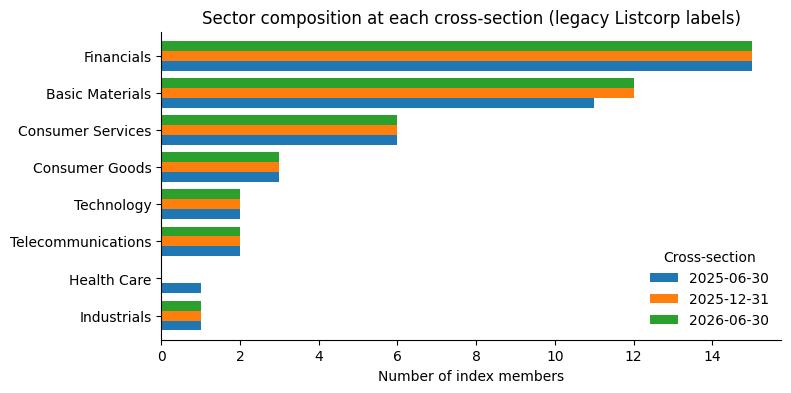

In [5]:
sector_counts = table(pd.crosstab(data.sector_label, data.decision_date), 'sector_counts')
fig, ax = plt.subplots(figsize=(8, 4))
sector_counts.sort_values(DATES[0]).plot.barh(ax=ax, width=0.8)
ax.set_xlabel('Number of index members'); ax.set_ylabel('')
ax.set_title('Sector composition at each cross-section (legacy Listcorp labels)')
ax.legend(title='Cross-section', frameon=False)
save(fig, 'eda_sector_composition'); plt.show()

Sector labels are **not** used to fit any model. They are used only afterwards, to compare with the clusters.
The labels are legacy Listcorp categories and are not independently verified historical ICB classifications.

### 2.4 Descriptive statistics
Medians and skewness of the ten modelling features at each date (native units: ZAR, shares, ratios).

In [6]:
stats_rows = []
for d in DATES:
    s = snaps[d][FEATURES]
    stats_rows.append(pd.DataFrame({'date': d, 'feature': NAMES, 'median': s.median().values,
                                    'mean': s.mean().values, 'std': s.std().values,
                                    'min': s.min().values, 'max': s.max().values, 'skew': s.skew().values}))
describe = table(pd.concat(stats_rows), 'descriptive_statistics', index=False)
describe.pivot(index='feature', columns='date', values=['median', 'skew']).loc[NAMES]

median                                   skew  \
date              2025-06-30    2025-12-31    2026-06-30 2025-06-30   
feature                                                               
1y return       1.107605e-01  1.947077e-01  1.118476e-01  -0.000871   
Avg volume      1.534909e+06  1.572320e+06  1.629171e+06   2.277893   
Market cap      1.431642e+11  1.712493e+11  1.562087e+11   2.201627   
Beta            1.055951e+00  8.801319e-01  5.638668e-01   0.725528   
Shares out      8.294584e+08  8.919062e+08  8.850165e+08   1.677737   
Revenue         9.824454e+10  9.824454e+10  1.156970e+11   2.769304   
EPS             1.277150e+01  1.394900e+01  1.394900e+01   5.111764   
Volatility      2.613748e-01  2.743391e-01  2.446734e-01   1.253408   
Div. yield      2.635855e-02  2.929574e-02  3.815014e-02   0.531125   
Earnings yield  5.136140e-02  5.716446e-02  6.093721e-02  -4.092619   

                                      
date           2025-12-31 2026-06-30  
feature                               
1y return        1.884050   0.717907  
Avg volume       2.442079   2.225048  
Market cap       1.968104   2.338347  
Beta             0.983128   1.284794  
Shares out       3.253252   3.196204  
Revenue          5.355344   5.508909  
EPS              1.637890   1.340373  
Volatility       1.306200   1.247727  
Div. yield       0.361442   0.197429  
Earnings yield  -0.477587  -0.754653

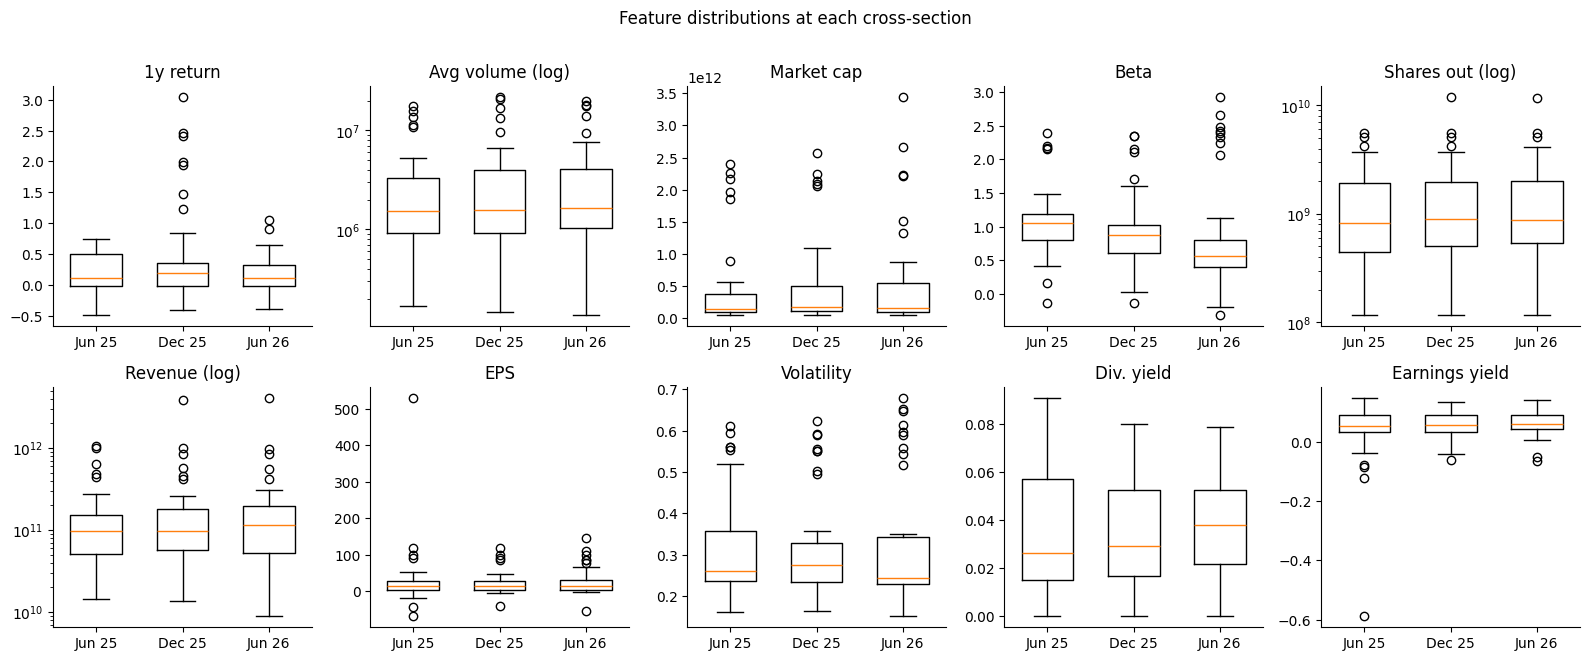

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for ax, feature, name in zip(axes.flat, FEATURES, NAMES):
    values = [snaps[d][feature] for d in DATES]
    ax.boxplot(values, tick_labels=['Jun 25', 'Dec 25', 'Jun 26'], widths=0.6)
    low, high = min(v.min() for v in values), max(v.max() for v in values)
    if low > 0 and high / low > 100:
        ax.set_yscale('log'); name += ' (log)'
    ax.set_title(name)
fig.suptitle('Feature distributions at each cross-section', y=1.01)
fig.tight_layout(); save(fig, 'eda_feature_distributions'); plt.show()

Size variables (market cap, shares, volume, revenue) are strongly right-skewed. A few very large firms
therefore dominate MinMax-scaled distances. This is a known limitation of the baseline specification
and is not changed here.

### 2.5 Correlations (June 2025, the preprocessing fit date)

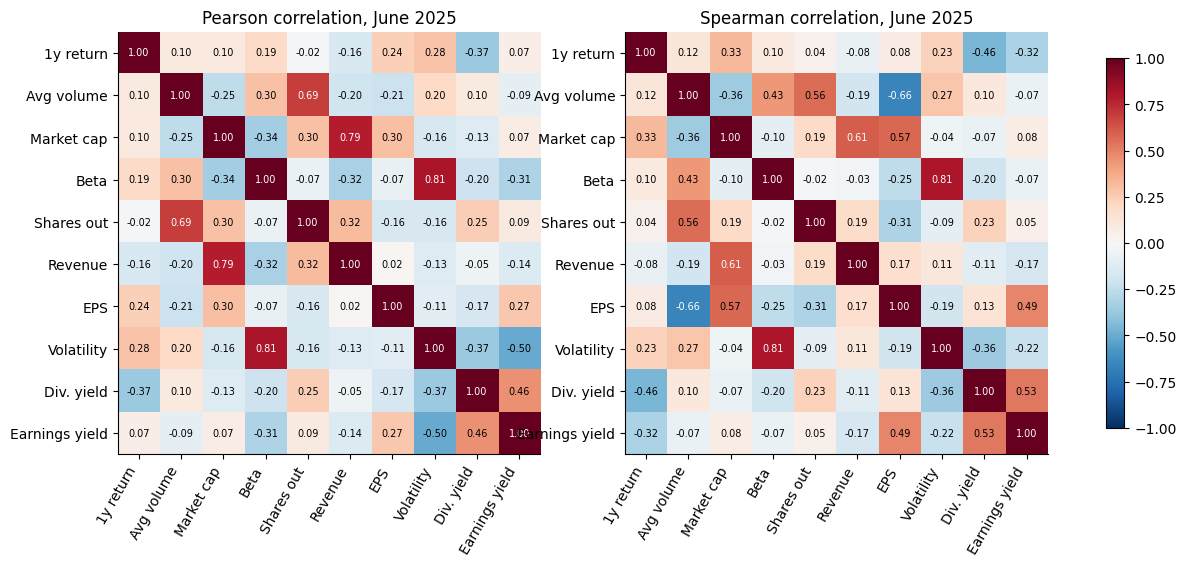

,feature_a,feature_b,pearson
27,Beta,Volatility,0.814852
19,Market cap,Revenue,0.786905


In [8]:
june = snaps[DATES[0]][FEATURES].set_axis(NAMES, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, method in zip(axes, ['pearson', 'spearman']):
    corr = june.corr(method=method)
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=60, ha='right'); ax.set_yticks(range(len(NAMES)), NAMES)
    for i, j in product(range(len(NAMES)), repeat=2):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
    ax.set_title(f'{method.title()} correlation, June 2025')
fig.colorbar(im, ax=axes, shrink=0.8); save(fig, 'eda_correlations'); plt.show()

pairs = [(NAMES[i], NAMES[j], june.corr().iloc[i, j]) for i, j in combinations(range(len(NAMES)), 2)]
high = pd.DataFrame(pairs, columns=['feature_a', 'feature_b', 'pearson']).query('abs(pearson) >= 0.7')
table(high.sort_values('pearson', key=abs, ascending=False), 'high_correlations', index=False)

Unlike the original sample, a few pairs are near or above 0.8 (for example beta with volatility, and market cap with revenue).
All ten features are kept so that the specification stays fixed. Correlated size and risk variables give those dimensions
extra weight, which should be stated in the paper.

## 3. Preprocessing
MinMax scaling is fitted **only on June 2025** and then applied unchanged to December 2025 and June 2026.
This avoids letting future information shape the scale. As a result, later values can fall outside [0, 1].

In [9]:
X = {d: scaler.transform(A.numeric_matrix(snaps[d])) for d in DATES}
outside = pd.DataFrame({d: ((X[d] < 0) | (X[d] > 1)).sum(axis=0) for d in DATES}, index=NAMES)
print('Scaled values outside [0, 1] per feature (expected to be 0 for June 2025):')
outside.T

Scaled values outside [0, 1] per feature (expected to be 0 for June 2025):


,1y return,Avg volume,Market cap,Beta,Shares out,Revenue,EPS,Volatility,Div. yield,Earnings yield
2025-06-30,0,0,0,0,0,0,0,1,0,0
2025-12-31,8,3,2,1,2,2,0,1,0,0
2026-06-30,2,3,4,6,1,3,0,5,0,0


## 4. Model comparison: nine combinations at each date
This corresponds to the paper's Table 2. Each date is fitted independently: the method is applied again to each
cross-section rather than trained on one date and used to predict the next.

Two kinds of score are reported:
* **in the embedding** (the 2-D map that was clustered), as in the paper; and
* **in the common 10-feature space**, which allows a fair comparison across PCA, t-SNE and UMAP.
  t-SNE and UMAP are designed to pull neighbours together, so embedding scores flatter them.

Silhouette: higher is better. Davies–Bouldin: lower is better. DBSCAN scores exclude noise points, so coverage is shown.

In [10]:
REPS, ALGOS = ['pca', 'tsne', 'umap'], ['hierarchical', 'kmeans', 'dbscan']
embeddings, rows = {}, []
for d in DATES:
    for rep in REPS:
        z = embeddings[d, rep] = A.embed(X[d], rep, SEED)
        for algo in ALGOS:
            y = A.cluster(z, algo, SEED, K)
            rows.append(dict(date=d, reduction=rep, clustering=algo, **A.scores(X[d], z, y, snaps[d].sector_label)))
comparison = pd.DataFrame(rows)
cols = ['n_clusters', 'coverage', 'silhouette_embedding', 'davies_bouldin_embedding', 'silhouette_features']
table(comparison[['date', 'reduction', 'clustering'] + cols + ['sector_ari', 'sector_nmi']], 'model_comparison', index=False)
comparison.pivot_table(index=['reduction', 'clustering'], columns='date',
                       values=['silhouette_embedding', 'davies_bouldin_embedding', 'silhouette_features']).round(3)

C:\Users\HP\Documents\GitHub\JSE-Top-40-Clustering\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


davies_bouldin_embedding                        \
date                                 2025-06-30 2025-12-31 2026-06-30   
reduction clustering                                                    
pca       dbscan                          0.431      0.348      0.310   
          hierarchical                    0.416      0.371      0.446   
          kmeans                          0.555      0.496      0.629   
tsne      dbscan                          0.662      0.532      0.484   
          hierarchical                    0.429      0.447      0.407   
          kmeans                          0.557      0.439      0.407   
umap      dbscan                          0.680      0.627      0.255   
          hierarchical                    0.689      0.548      0.613   
          kmeans                          0.697      0.642      0.613   

                       silhouette_embedding                        \
date                             2025-06-30 2025-12-31 2026-06-30   
reduction clustering                                                
pca       dbscan                      0.540      0.752      0.718   
          hierarchical                0.426      0.498      0.466   
          kmeans                      0.397      0.447      0.414   
tsne      dbscan                      0.338      0.505      0.507   
          hierarchical                0.571      0.598      0.641   
          kmeans                      0.529      0.618      0.641   
umap      dbscan                      0.287      0.433      0.759   
          hierarchical                0.406      0.501      0.542   
          kmeans                      0.421      0.523      0.543   

                       silhouette_features                        
date                            2025-06-30 2025-12-31 2026-06-30  
reduction clustering                                              
pca       dbscan                     0.393      0.556      0.427  
          hierarchical               0.177      0.285      0.279  
          kmeans                     0.072      0.151      0.093  
tsne      dbscan                     0.294      0.171      0.297  
          hierarchical               0.182      0.177      0.223  
          kmeans                     0.177      0.208      0.223  
umap      dbscan                     0.202      0.473      0.321  
          hierarchical               0.117      0.153      0.209  
          kmeans                     0.125      0.170      0.182

In [11]:
# Check: these numbers must match the archived tracked run (same code, data and seed).
archived = pd.read_csv(ROOT / 'experiments/runs/final-full-42/model_comparison.csv')
mine = comparison.assign(model=comparison.reduction + '_' + comparison.clustering)
check = mine.merge(archived, left_on=['date', 'model'], right_on=['decision_date', 'model'], suffixes=('', '_archived'))
for c in ['silhouette_embedding', 'silhouette_features', 'davies_bouldin_embedding']:
    np.testing.assert_allclose(check[c].astype(float), check[c + '_archived'].astype(float), rtol=1e-6, equal_nan=True)
print(f'Matches the archived run final-full-42 on all {len(check)} model/date rows.')

Matches the archived run final-full-42 on all 27 model/date rows.


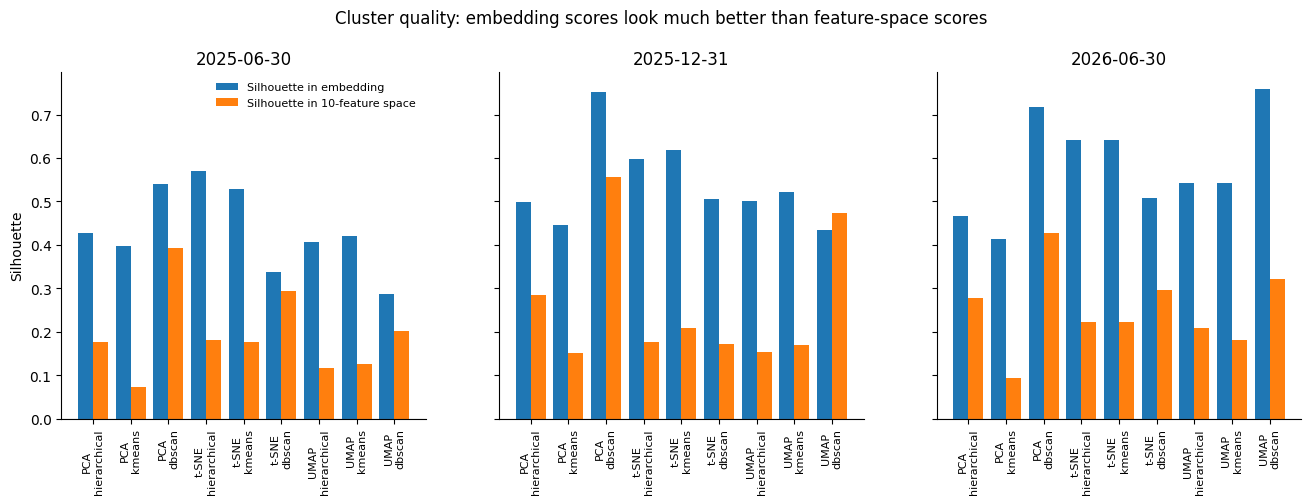

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
labels = [f'{r.upper() if r == "pca" else ("t-SNE" if r == "tsne" else "UMAP")}\n{a}' for r, a in product(REPS, ALGOS)]
for ax, d in zip(axes, DATES):
    sub = comparison[comparison.date == d]
    pos = np.arange(len(sub))
    ax.bar(pos - 0.2, sub.silhouette_embedding, 0.4, label='Silhouette in embedding')
    ax.bar(pos + 0.2, sub.silhouette_features, 0.4, label='Silhouette in 10-feature space')
    ax.set_xticks(pos, labels, rotation=90, fontsize=8); ax.set_title(d); ax.axhline(0, color='grey', lw=0.8)
axes[0].set_ylabel('Silhouette'); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Cluster quality: embedding scores look much better than feature-space scores', y=1.02)
save(fig, 'model_comparison_silhouette'); plt.show()

**Reading.** As in the paper, t-SNE + hierarchical has among the highest embedding silhouettes. In the common
feature space, however, every combination scores much lower (about 0.1–0.3). The 2-D maps make the groups look
more separated than they are in the financial data. The paper's own caveat (Section 4.1) is now quantified.

## 5. Baseline model: t-SNE + hierarchical clustering (k = 8)
Settings: MinMax, 2-D t-SNE (perplexity 5, learning rate 10, 300 iterations), average linkage, Manhattan distance, eight clusters.
These are the recovered historical settings. The original notebook was not recovered, so this is a reconstruction,
not an exact reproduction.

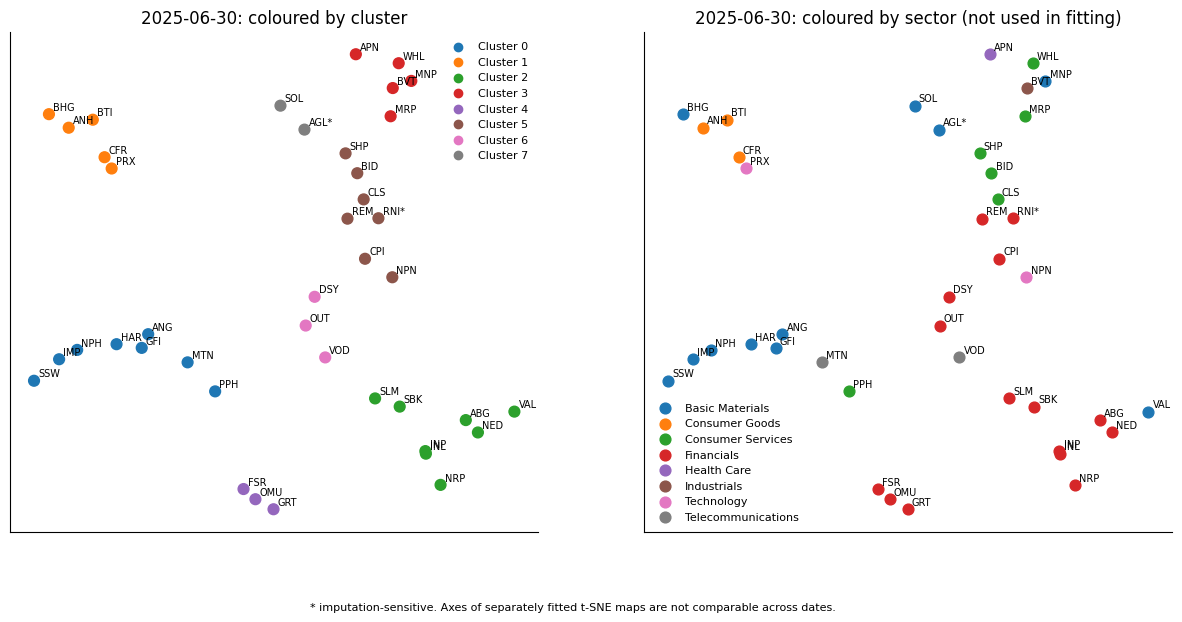

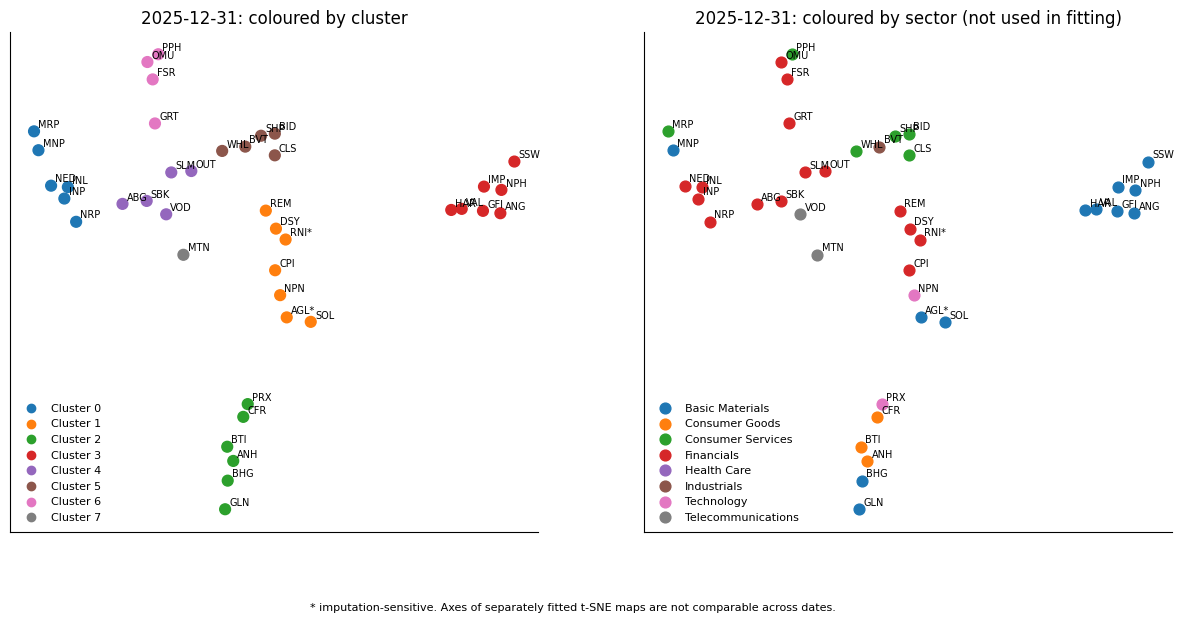

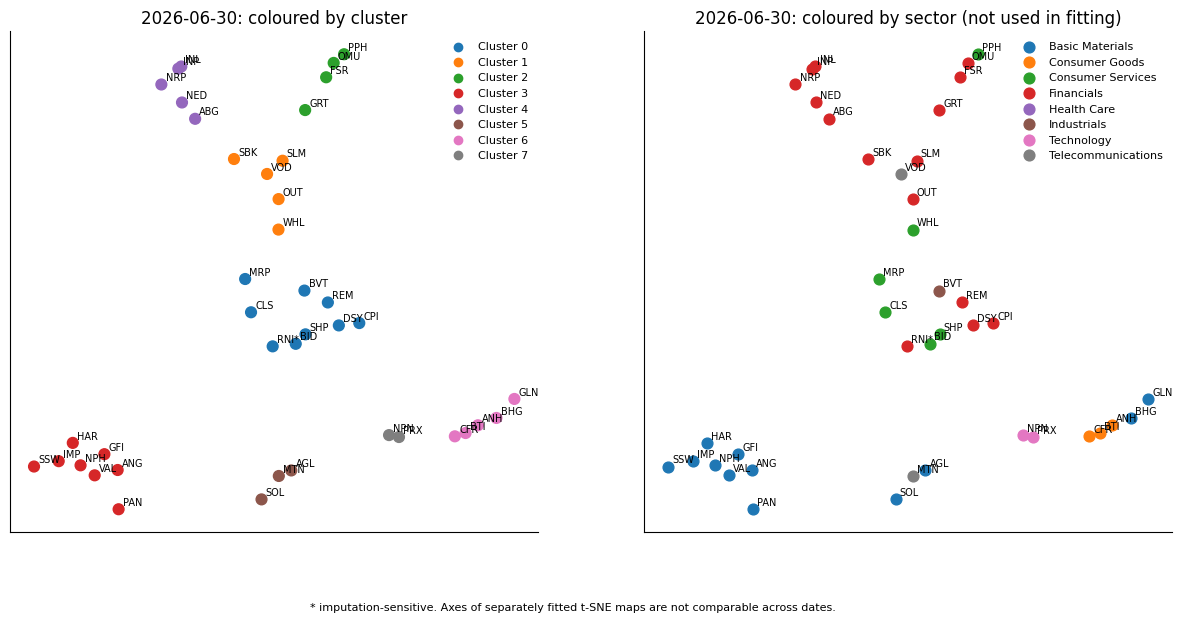

In [13]:
base = {}
for d in DATES:
    z = embeddings[d, 'tsne']
    base[d] = snaps[d].assign(cluster=A.cluster(z, 'hierarchical', SEED, K), tsne_1=z[:, 0], tsne_2=z[:, 1])
assignments = table(pd.concat(base.values())[['decision_date', 'ticker', 'company', 'sector_label', 'cluster',
                                              'tsne_1', 'tsne_2', 'fundamentals_imputed', 'volume_imputed']],
                    'baseline_assignments', index=False)

sectors = sorted(data.sector_label.unique())
sector_colour = dict(zip(sectors, plt.cm.tab10.colors))
for d in DATES:
    b = base[d]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    axes[0].scatter(b.tsne_1, b.tsne_2, c=[plt.cm.tab10(c) for c in b.cluster], s=60)
    for s in sectors:
        m = b.sector_label == s
        axes[1].scatter(b.tsne_1[m], b.tsne_2[m], color=sector_colour[s], s=60, label=s)
    for ax in axes:
        for _, r in b.iterrows():
            ax.annotate(r.ticker + ('*' if r.fundamentals_imputed or r.volume_imputed else ''),
                        (r.tsne_1, r.tsne_2), fontsize=7, xytext=(3, 3), textcoords='offset points')
        ax.set_xticks([]); ax.set_yticks([])
    for c in sorted(b.cluster.unique()):
        axes[0].scatter([], [], color=plt.cm.tab10(c), label=f'Cluster {c}')
    axes[0].legend(frameon=False, fontsize=8, loc='best'); axes[1].legend(frameon=False, fontsize=8, loc='best')
    axes[0].set_title(f'{d}: coloured by cluster'); axes[1].set_title(f'{d}: coloured by sector (not used in fitting)')
    fig.text(0.5, -0.01, '* imputation-sensitive. Axes of separately fitted t-SNE maps are not comparable across dates.',
             ha='center', fontsize=8)
    save(fig, f'tsne_clusters_{d}'); plt.show()

### 5.1 Dendrograms
The dendrogram is built with SciPy (average linkage, city-block distance). The next cell checks that cutting it at eight clusters gives exactly the same groups as the pipeline.

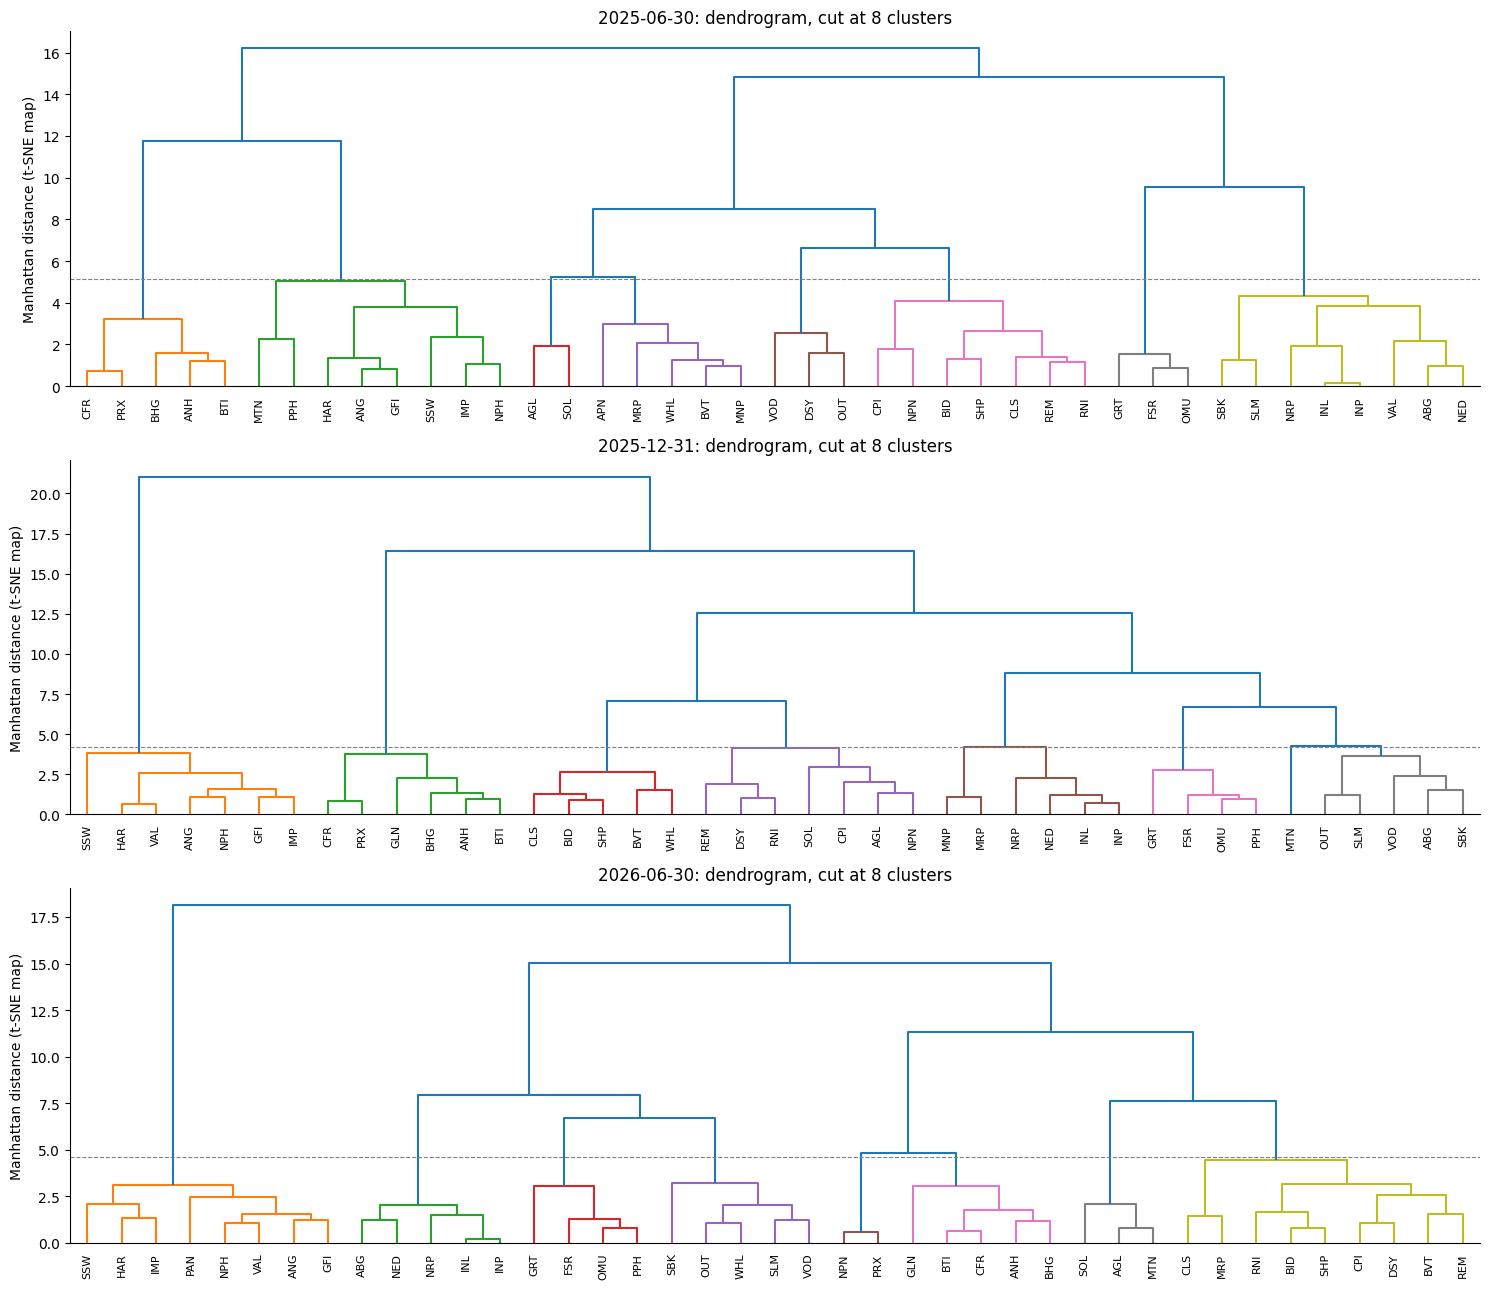

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13))
for ax, d in zip(axes, DATES):
    b = base[d]
    Z = linkage(b[['tsne_1', 'tsne_2']].to_numpy(), method='average', metric='cityblock')
    assert adjusted_rand_score(b.cluster, fcluster(Z, K, 'maxclust')) == 1.0   # same partition as the pipeline
    cut = (Z[-K, 2] + Z[-K + 1, 2]) / 2
    dendrogram(Z, labels=b.ticker.tolist(), color_threshold=cut, ax=ax, leaf_font_size=8)
    ax.axhline(cut, ls='--', color='grey', lw=0.8); ax.set_title(f'{d}: dendrogram, cut at {K} clusters')
    ax.set_ylabel('Manhattan distance (t-SNE map)')
fig.tight_layout(); save(fig, 'dendrograms'); plt.show()

### 5.2 Who is in each cluster, and what characterises it

In [15]:
rows = []
for d in DATES:
    for c, g in base[d].groupby('cluster'):
        rows.append(dict(date=d, cluster=c, n=len(g), firms=', '.join(g.ticker),
                         sectors='; '.join(f'{s} ({n})' for s, n in g.sector_label.value_counts().items())))
members_table = table(pd.DataFrame(rows), 'cluster_members', index=False)
with pd.option_context('display.max_colwidth', 120):
    display(members_table)

,date,cluster,n,firms,sectors
0,2025-06-30,0,8,"ANG, GFI, HAR, IMP, MTN, NPH, PPH, SSW",Basic Materials (6); Telecommunications (1); Consumer Services (1)
1,2025-06-30,1,5,"ANH, BHG, BTI, CFR, PRX",Consumer Goods (3); Basic Materials (1); Technology (1)
2,2025-06-30,2,8,"ABG, INL, INP, NED, NRP, SBK, SLM, VAL",Financials (7); Basic Materials (1)
3,2025-06-30,3,5,"APN, BVT, MNP, MRP, WHL",Consumer Services (2); Health Care (1); Industrials (1); Basic Materials (1)
4,2025-06-30,4,3,"FSR, GRT, OMU",Financials (3)
5,2025-06-30,5,7,"BID, CLS, CPI, NPN, REM, RNI, SHP",Consumer Services (3); Financials (3); Technology (1)
6,2025-06-30,6,3,"DSY, OUT, VOD",Financials (2); Telecommunications (1)
7,2025-06-30,7,2,"AGL, SOL",Basic Materials (2)
8,2025-12-31,0,6,"INL, INP, MNP, MRP, NED, NRP",Financials (4); Basic Materials (1); Consumer Services (1)
9,2025-12-31,1,7,"AGL, CPI, DSY, NPN, REM, RNI, SOL",Financials (4); Basic Materials (2); Technology (1)


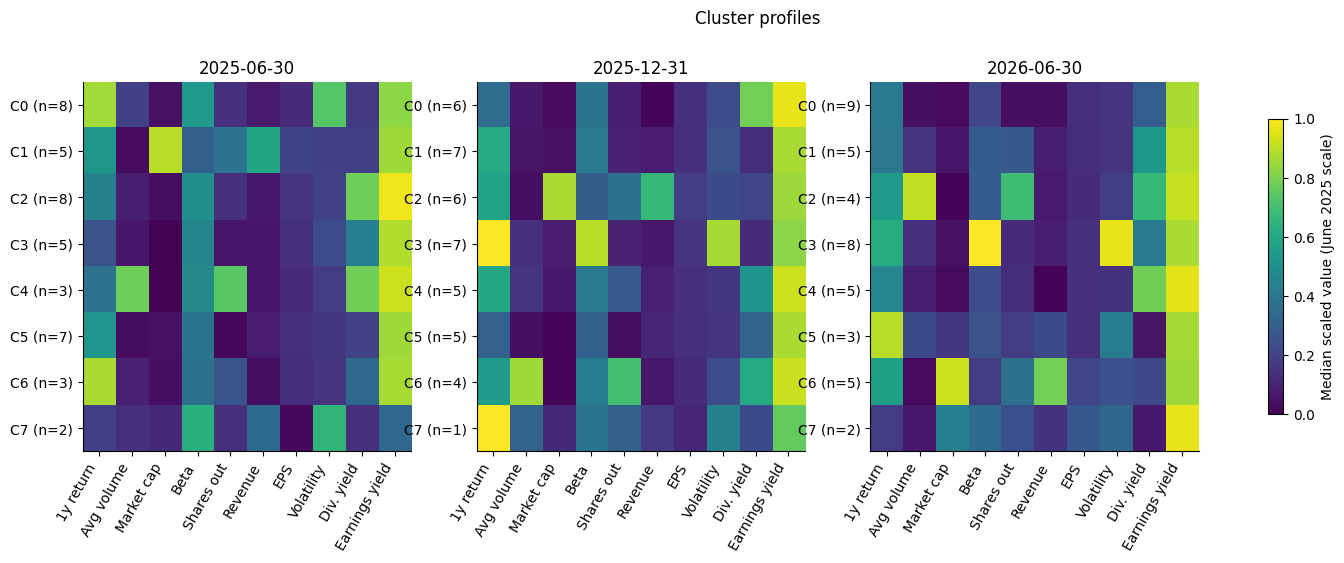

In [16]:
# Median June-2025-scaled feature values per cluster: the "profile" of each group.
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, d in zip(axes, DATES):
    profile = pd.DataFrame(X[d], columns=NAMES).groupby(base[d].cluster.values).median()
    im = ax.imshow(profile, cmap='viridis', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=60, ha='right')
    ax.set_yticks(range(len(profile)), [f'C{c} (n={(base[d].cluster == c).sum()})' for c in profile.index])
    ax.set_title(d)
fig.colorbar(im, ax=axes, shrink=0.8, label='Median scaled value (June 2025 scale)')
fig.suptitle('Cluster profiles', y=1.03); save(fig, 'cluster_profiles'); plt.show()

## 6. Robustness
### 6.1 Is eight clusters the right number?
k = 8 is the historical baseline (chosen to match the eight sector categories), not a data-driven optimum. Here k runs from 2 to 10.

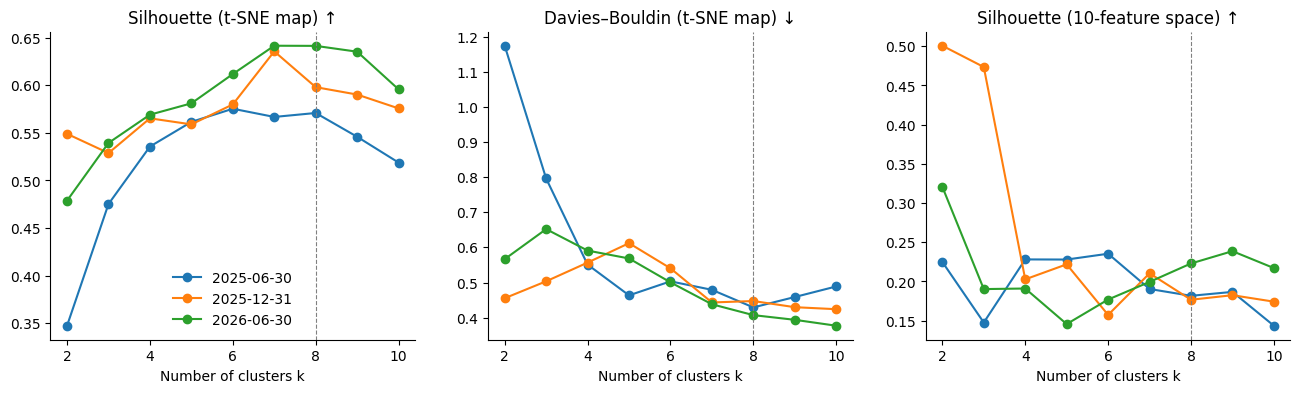

In [17]:
rows = []
for d in DATES:
    for k in range(2, 11):
        y = A.cluster(embeddings[d, 'tsne'], 'hierarchical', SEED, k)
        rows.append(dict(date=d, k=k, **A.scores(X[d], embeddings[d, 'tsne'], y, snaps[d].sector_label)))
k_sens = table(pd.DataFrame(rows)[['date', 'k', 'silhouette_embedding', 'davies_bouldin_embedding',
                                   'silhouette_features', 'sector_ari']], 'k_sensitivity', index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (metric, title) in zip(axes, [('silhouette_embedding', 'Silhouette (t-SNE map) ↑'),
                                      ('davies_bouldin_embedding', 'Davies–Bouldin (t-SNE map) ↓'),
                                      ('silhouette_features', 'Silhouette (10-feature space) ↑')]):
    for d in DATES:
        s = k_sens[k_sens.date == d]; ax.plot(s.k, s[metric], marker='o', label=d)
    ax.axvline(K, color='grey', ls='--', lw=0.8); ax.set_xlabel('Number of clusters k'); ax.set_title(title)
axes[0].legend(frameon=False); save(fig, 'k_sensitivity'); plt.show()

### 6.2 Random-seed stability
t-SNE is random. The SACJ paper reported ARI = NMI = 1.0 across five seeds. Here the baseline is refitted with seeds 42–46 at each date
and every pair of runs is compared (10 pairs per date).

In [18]:
seed_embed = {(d, s): A.embed(X[d], 'tsne', s) for d in DATES for s in SEEDS}
seed_labels = {(d, s): A.cluster(seed_embed[d, s], 'hierarchical', s, K) for d in DATES for s in SEEDS}
assert all((seed_labels[d, SEED] == base[d].cluster.values).all() for d in DATES)

rows = [dict(date=d, seed_a=a, seed_b=b, ari=adjusted_rand_score(seed_labels[d, a], seed_labels[d, b]),
             nmi=normalized_mutual_info_score(seed_labels[d, a], seed_labels[d, b]))
        for d in DATES for a, b in combinations(SEEDS, 2)]
seed_pairs = table(pd.DataFrame(rows), 'seed_stability_pairs', index=False)
seed_summary = table(seed_pairs.groupby('date')[['ari', 'nmi']].agg(['mean', 'min', 'max']), 'seed_stability_summary')
seed_summary.round(3)

ari                  nmi              
             mean    min    max   mean    min    max
date                                                
2025-06-30  0.727  0.526  0.898  0.872  0.789  0.952
2025-12-31  0.920  0.883  1.000  0.959  0.932  1.000
2026-06-30  0.934  0.836  1.000  0.967  0.919  1.000

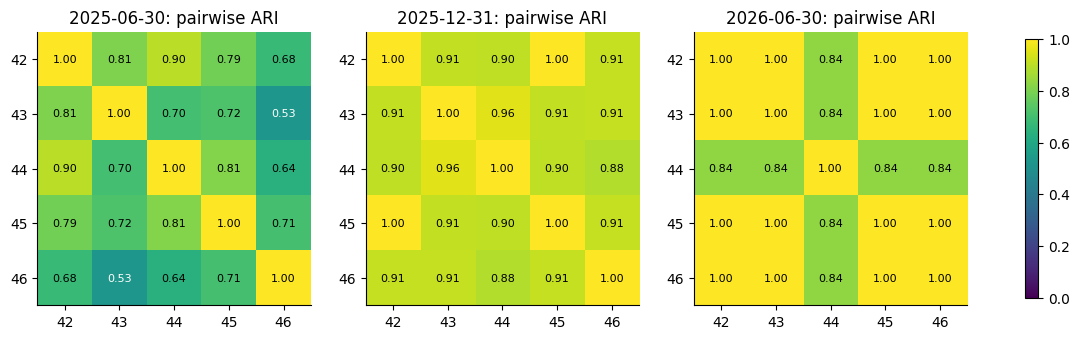

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, d in zip(axes, DATES):
    m = np.array([[adjusted_rand_score(seed_labels[d, a], seed_labels[d, b]) for b in SEEDS] for a in SEEDS])
    im = ax.imshow(m, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(5), SEEDS); ax.set_yticks(range(5), SEEDS); ax.set_title(f'{d}: pairwise ARI')
    for i, j in product(range(5), repeat=2):
        ax.text(j, i, f'{m[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if m[i, j] < 0.6 else 'black')
fig.colorbar(im, ax=axes, shrink=0.8); save(fig, 'seed_stability'); plt.show()

**Reading.** Stability is good but **not perfect**, especially in June 2025. The paper's earlier claim of perfect seed
stability should not be carried over. For this reason, every firm-level result below is reported as
*the share of the five seeds in which it holds*, rather than from one seed. (Seed variation is not bootstrap
uncertainty: it does not resample firms.)

## 7. Sector comparison and sector-divergent firms
Agreement between clusters and sector labels (ARI, NMI) is descriptive. k = 8 was not tuned to maximise it.

**Sector-divergent firm** (the paper's anomaly concept), defined precisely: in a given run, a cluster has a *dominant sector* if one sector has
strictly more members than any other, and at least two. A firm in such a cluster that belongs to a different sector is *sector-divergent*.
Firms in singleton clusters, or in clusters with no dominant sector, are not called divergent.

In [20]:
rows = [dict(date=d, seed=s, ari=adjusted_rand_score(snaps[d].sector_label, seed_labels[d, s]),
             nmi=normalized_mutual_info_score(snaps[d].sector_label, seed_labels[d, s])) for d in DATES for s in SEEDS]
sector_agree = pd.DataFrame(rows)
table(sector_agree.groupby('date')[['ari', 'nmi']].agg(['mean', 'min', 'max']), 'sector_agreement').round(3)

ari                  nmi              
             mean    min    max   mean    min    max
date                                                
2025-06-30  0.220  0.164  0.268  0.521  0.472  0.560
2025-12-31  0.256  0.243  0.271  0.552  0.534  0.575
2026-06-30  0.303  0.292  0.306  0.596  0.575  0.601

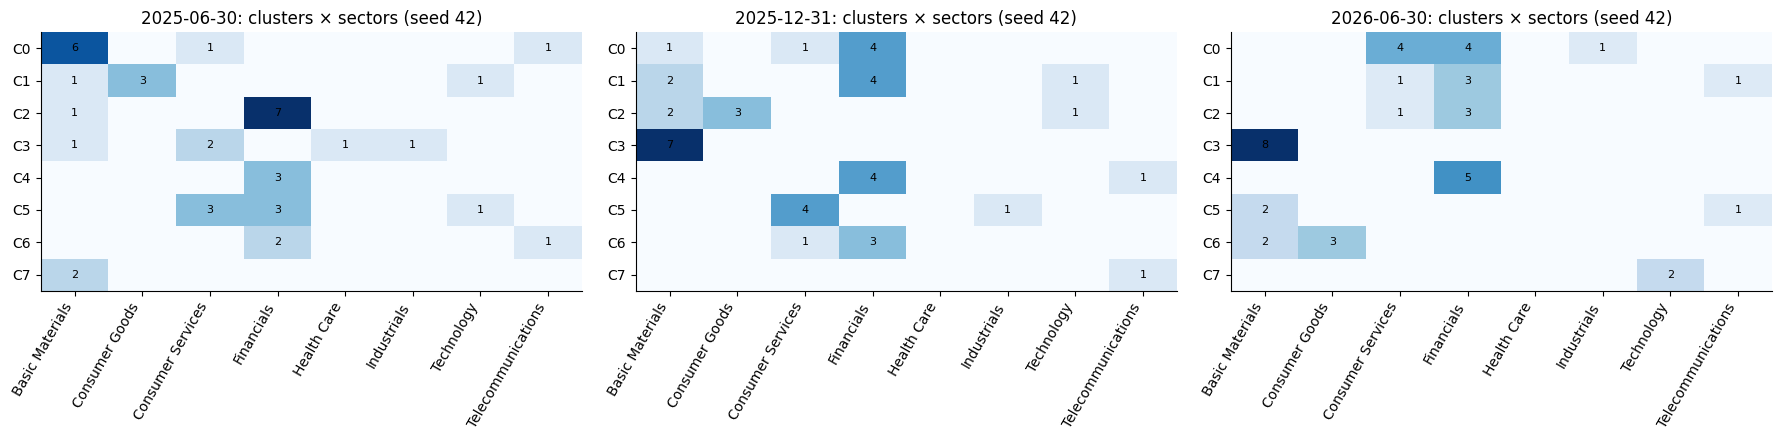

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, d in zip(axes, DATES):
    ct = pd.crosstab(base[d].cluster, base[d].sector_label).reindex(columns=sectors, fill_value=0)
    ax.imshow(ct, cmap='Blues', aspect='auto')
    ax.set_xticks(range(len(sectors)), sectors, rotation=60, ha='right'); ax.set_yticks(range(len(ct)), [f'C{c}' for c in ct.index])
    for i, j in product(range(ct.shape[0]), range(ct.shape[1])):
        if ct.iloc[i, j]:
            ax.text(j, i, ct.iloc[i, j], ha='center', va='center', fontsize=8)
    ax.set_title(f'{d}: clusters × sectors (seed {SEED})')
fig.tight_layout(); save(fig, 'cluster_sector_crosstab'); plt.show()

In [22]:
def divergence_status(frame, labels):
    # 'divergent', 'aligned', 'no dominant sector' or 'singleton' for each firm in one run.
    status = pd.Series(index=frame.ticker.values, dtype=object)
    for c in np.unique(labels):
        in_c = labels == c
        sec = frame.sector_label.values[in_c]
        counts = pd.Series(sec).value_counts()
        if in_c.sum() == 1:
            status[frame.ticker.values[in_c]] = 'singleton'
        elif counts.iloc[0] >= 2 and (len(counts) == 1 or counts.iloc[0] > counts.iloc[1]):
            status[frame.ticker.values[in_c]] = np.where(sec == counts.index[0], 'aligned', 'divergent:' + counts.index[0])
        else:
            status[frame.ticker.values[in_c]] = 'no dominant sector'
    return status

rows = []
for d in DATES:
    runs = pd.DataFrame({s: divergence_status(snaps[d], seed_labels[d, s]) for s in SEEDS})
    for ticker, r in runs.iterrows():
        div = r[r.str.startswith('divergent')]
        rows.append(dict(date=d, ticker=ticker, sector=info.loc[ticker, 'sector_label'],
                         divergent_share=len(div) / len(SEEDS),
                         usual_cluster_sector=div.str.replace('divergent:', '').mode().iat[0] if len(div) else '',
                         singleton_share=(r == 'singleton').mean(),
                         imputation_sensitive=ticker in {'RNI', 'AGL'}))
divergence = table(pd.DataFrame(rows), 'sector_divergence_all', index=False)
robust = divergence[divergence.divergent_share >= 0.8]
robust_wide = robust.pivot_table(index=['ticker', 'sector'], columns='date', values='divergent_share')
print('Firms that are sector-divergent in at least 4 of 5 seeds (share of seeds shown):')
table(robust_wide, 'sector_divergence_robust').fillna('–')

Firms that are sector-divergent in at least 4 of 5 seeds (share of seeds shown):


,date,2025-06-30,2025-12-31,2026-06-30
ticker,sector,,,
APN,Health Care,0.8,–,–
BHG,Basic Materials,1.0,1.0,1.0
BVT,Industrials,0.8,1.0,–
GLN,Basic Materials,–,1.0,1.0
MNP,Basic Materials,–,1.0,–
MRP,Consumer Services,–,1.0,–
MTN,Telecommunications,–,–,1.0
NPN,Technology,–,1.0,–
PPH,Consumer Services,–,1.0,1.0


In [23]:
persistent = robust_wide.dropna()
print(f'{len(persistent)} firms are robustly sector-divergent at all three dates:')
display(persistent.reset_index()[['ticker', 'sector']].join(
    robust.groupby('ticker').usual_cluster_sector.agg(lambda s: ', '.join(sorted(set(s)))), on='ticker'))

2 firms are robustly sector-divergent at all three dates:


,ticker,sector,usual_cluster_sector
0,BHG,Basic Materials,Consumer Goods
1,VOD,Telecommunications,Financials


## 8. Hotelling's T² outliers
The paper computed T² in the 2-D map, with the critical value `p(n−1)/(n−p) · F(0.95; p, n−p)`
(n = 40, p = 2 gives about 6.66, as in the paper). The same rule is used here with n = 41.
The paper's own future-work note asked for a comparison in the original feature space, so T² is also computed
in the 10-feature scaled space (p = 10). t-SNE-space flags are reported as the share of five seeds flagged.

In [24]:
def hotelling(z, alpha=0.05):
    n, p = z.shape
    centred = z - z.mean(axis=0)
    t2 = np.einsum('ij,jk,ik->i', centred, np.linalg.pinv(np.cov(z, rowvar=False)), centred)
    return t2, p * (n - 1) / (n - p) * stats.f.ppf(1 - alpha, p, n - p)

print('Check against the paper (n=40, p=2):', round(2 * 39 / 38 * stats.f.ppf(0.95, 2, 38), 2))
rows = []
for d in DATES:
    t2_feat, crit_feat = hotelling(X[d])
    flags = np.array([hotelling(seed_embed[d, s])[0] > hotelling(seed_embed[d, s])[1] for s in SEEDS])
    t2_map, crit_map = hotelling(seed_embed[d, SEED])
    for i, t in enumerate(snaps[d].ticker):
        rows.append(dict(date=d, ticker=t, sector=info.loc[t, 'sector_label'],
                         t2_tsne_seed42=t2_map[i], tsne_flag_share=flags[:, i].mean(), tsne_critical=crit_map,
                         t2_features=t2_feat[i], feature_flag=t2_feat[i] > crit_feat, feature_critical=crit_feat,
                         imputation_sensitive=t in {'RNI', 'AGL'}))
t2 = table(pd.DataFrame(rows), 'hotelling_t2', index=False)
print(t2.groupby('date')[['tsne_critical', 'feature_critical']].first().round(2))
print('Firms above the t-SNE-map threshold in at least one seed:',
      t2.groupby('date').tsne_flag_share.apply(lambda s: int((s > 0).sum())).to_dict())
print('Firms above the feature-space threshold:', t2.groupby('date').feature_flag.sum().to_dict())
t2_flagged = t2[(t2.tsne_flag_share >= 0.8) | t2.feature_flag].sort_values(['date', 't2_features'], ascending=[True, False])
t2_flagged.round(2)

Check against the paper (n=40, p=2): 6.66
            tsne_critical  feature_critical
date                                       
2025-06-30           6.64             27.78
2025-12-31           6.64             27.78
2026-06-30           6.64             27.78
Firms above the t-SNE-map threshold in at least one seed: {'2025-06-30': 0, '2025-12-31': 0, '2026-06-30': 0}
Firms above the feature-space threshold: {'2025-06-30': 3, '2025-12-31': 1, '2026-06-30': 2}


,date,ticker,sector,t2_tsne_seed42,tsne_flag_share,tsne_critical,t2_features,feature_flag,feature_critical,imputation_sensitive
25,2025-06-30,NPN,Technology,0.61,0.0,6.64,37.13,True,27.78,False
36,2025-06-30,SOL,Basic Materials,1.60,0.0,6.64,34.32,True,27.78,False
30,2025-06-30,PRX,Technology,2.08,0.0,6.64,29.29,True,27.78,False
55,2025-12-31,GLN,Basic Materials,6.55,0.0,6.64,37.82,True,27.78,False
96,2026-06-30,GLN,Basic Materials,4.40,0.0,6.64,38.57,True,27.78,False
118,2026-06-30,SOL,Basic Materials,1.53,0.0,6.64,34.84,True,27.78,False


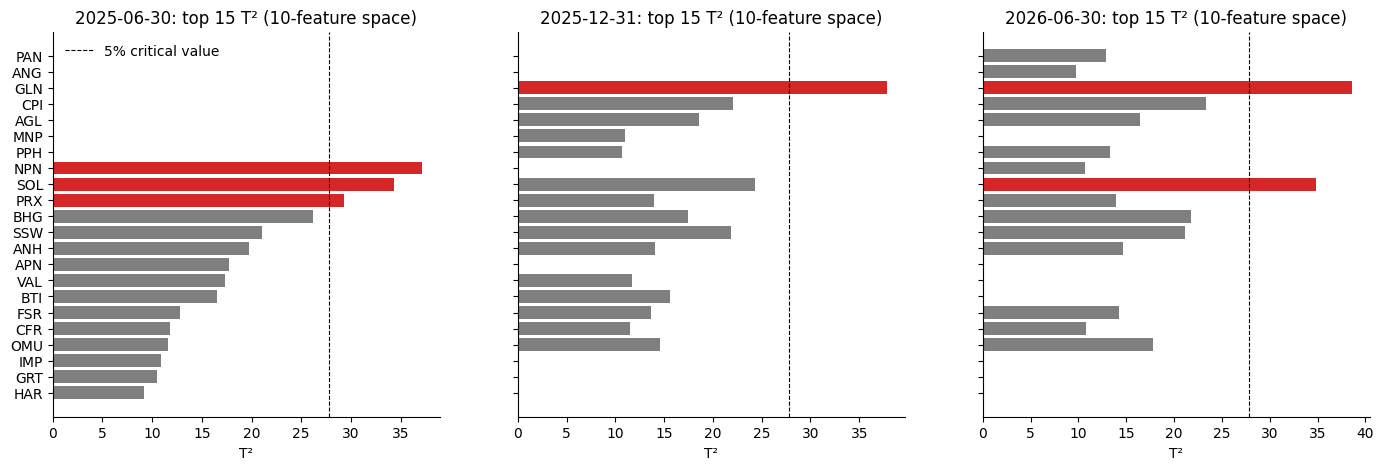

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, d in zip(axes, DATES):
    s = t2[t2.date == d].sort_values('t2_features', ascending=False).head(15)[::-1]
    ax.barh(s.ticker, s.t2_features, color=np.where(s.feature_flag, 'tab:red', 'tab:grey'))
    ax.axvline(s.feature_critical.iat[0], ls='--', color='black', lw=0.8, label='5% critical value')
    ax.set_title(f'{d}: top 15 T² (10-feature space)'); ax.set_xlabel('T²')
axes[0].legend(frameon=False); save(fig, 'hotelling_t2'); plt.show()

**Reading.** Feature-space T² flags are deterministic and do not depend on t-SNE. Map-space flags depend on the seed,
because each t-SNE map is different. With perplexity 5, t-SNE spreads firms fairly evenly across the map, so few or no firms
exceed the map-space threshold (see the counts printed above). This is a reason to report the feature-space version.
Firms flagged at several dates are the most defensible outliers.
The F-based threshold assumes approximately multivariate-normal data, which skewed financial variables violate,
so treat the flags as screening signals, not formal tests.

## 9. Changes over time
### 9.1 Entries and exits
Entering and exiting firms appear at only one of the two dates, so they have no "change". Instead we show where they sit
at the date they are present.

In [26]:
rows = []
for _, e in events.iterrows():
    before, after = e.period.split(' → ')
    d = after if e.event == 'entry' else before
    b = base[d]; c = b.loc[b.ticker == e.ticker, 'cluster'].iat[0]
    rows.append(dict(event=e.event, ticker=e.ticker, sector=e.sector_label, date_observed=d,
                     cluster=c, cluster_peers=', '.join(b.ticker[(b.cluster == c) & (b.ticker != e.ticker)])))
table(pd.DataFrame(rows), 'entry_exit_context', index=False)

,event,ticker,sector,date_observed,cluster,cluster_peers
0,entry,GLN,Basic Materials,2025-12-31,2,"ANH, BHG, BTI, CFR, PRX"
1,exit,APN,Health Care,2025-06-30,3,"BVT, MNP, MRP, WHL"
2,entry,PAN,Basic Materials,2026-06-30,3,"ANG, GFI, HAR, IMP, NPH, SSW, VAL"
3,exit,MNP,Basic Materials,2025-12-31,0,"INL, INP, MRP, NED, NRP"


### 9.2 Do continuing firms change peer group?
Cluster *numbers* are arbitrary and are refitted at each date, so they cannot be compared directly.
Two label-free comparisons are used, both restricted to the 40 firms present at both dates:

* **Partition agreement (ARI)** between dates. Importantly, it is compared with the agreement *between seeds on the same date*.
  If cross-date agreement is no lower than same-date seed agreement, the apparent "change" is indistinguishable from t-SNE randomness.
* **Peer-set overlap** for each firm: the Jaccard overlap of its cluster-mates at the two dates, averaged over all 25 seed pairs.
  This is compared with the same firm's overlap between seeds on the earlier date (its noise floor).

In [27]:
rows = []
for before, after in zip(DATES, DATES[1:]):
    common = sorted(members[before] & members[after])
    pos = {d: snaps[d].set_index('ticker').index.get_indexer(common) for d in (before, after)}
    for a, b in product(SEEDS, SEEDS):
        rows.append(dict(comparison=f'{before} → {after}', kind='across dates',
                         ari=adjusted_rand_score(seed_labels[before, a][pos[before]], seed_labels[after, b][pos[after]])))
for d in DATES:
    rows += [dict(comparison=d, kind='same date, different seeds', ari=r.ari) for r in seed_pairs[seed_pairs.date == d].itertuples()]
temporal = pd.DataFrame(rows)
table(temporal.groupby(['kind', 'comparison']).ari.describe()[['count', 'min', '50%', 'mean', 'max']], 'temporal_vs_seed_ari').round(3)

count    min    50%  \
kind                       comparison                                     
across dates               2025-06-30 → 2025-12-31   25.0  0.259  0.450   
                           2025-12-31 → 2026-06-30   25.0  0.573  0.626   
same date, different seeds 2025-06-30                10.0  0.526  0.714   
                           2025-12-31                10.0  0.883  0.910   
                           2026-06-30                10.0  0.836  1.000   

                                                     mean    max  
kind                       comparison                             
across dates               2025-06-30 → 2025-12-31  0.421  0.515  
                           2025-12-31 → 2026-06-30  0.620  0.669  
same date, different seeds 2025-06-30               0.727  0.898  
                           2025-12-31               0.920  1.000  
                           2026-06-30               0.934  1.000

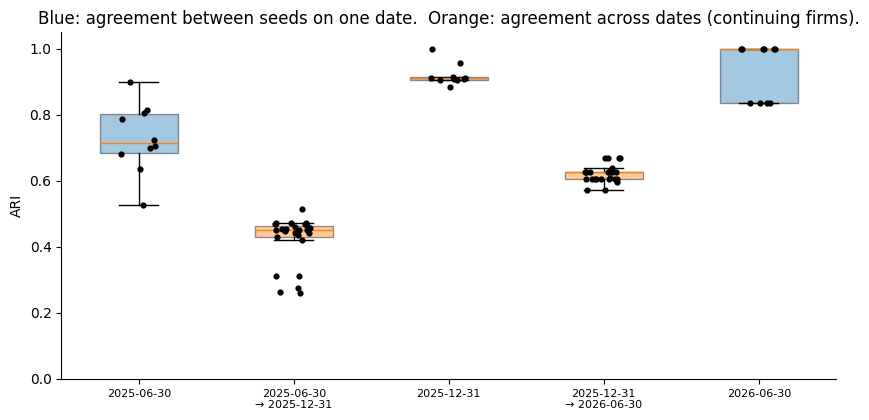

In [28]:
order = DATES[:1] + [f'{DATES[0]} → {DATES[1]}'] + DATES[1:2] + [f'{DATES[1]} → {DATES[2]}'] + DATES[2:]
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, name in enumerate(order):
    v = temporal[temporal.comparison == name].ari
    across = '→' in name
    ax.boxplot(v, positions=[i], widths=0.5, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor='tab:orange' if across else 'tab:blue', alpha=0.4))
    ax.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)), v, s=12, color='black', zorder=3)
ax.set_xticks(range(len(order)), [n.replace(' → ', '\n→ ') for n in order], fontsize=8)
ax.set_ylabel('ARI'); ax.set_ylim(0, 1.05)
ax.set_title('Blue: agreement between seeds on one date.  Orange: agreement across dates (continuing firms).')
save(fig, 'temporal_vs_seed_ari'); plt.show()

In [29]:
def peers(labels, tickers, keep):
    lab = dict(zip(tickers, labels))
    return {t: {u for u in keep if u != t and lab[u] == lab[t]} for t in keep}

def jaccard(a, b):
    return 1.0 if not a and not b else len(a & b) / len(a | b)

rows = []
for before, after in zip(DATES, DATES[1:]):
    common = sorted(members[before] & members[after])
    P = {(d, s): peers(seed_labels[d, s], snaps[d].ticker, common) for d in (before, after) for s in SEEDS}
    for t in common:
        across = np.mean([jaccard(P[before, a][t], P[after, b][t]) for a, b in product(SEEDS, SEEDS)])
        floor = np.mean([jaccard(P[before, a][t], P[before, b][t]) for a, b in combinations(SEEDS, 2)])
        rows.append(dict(period=f'{before} → {after}', ticker=t, sector=info.loc[t, 'sector_label'],
                         peer_overlap_across_dates=across, peer_overlap_same_date_seeds=floor,
                         drop_beyond_seed_noise=floor - across,
                         peers_before=', '.join(sorted(P[before, SEED][t])), peers_after=', '.join(sorted(P[after, SEED][t])),
                         interpretation='imputation-sensitive' if t in {'RNI', 'AGL'} else 'descriptive'))
peer_change = table(pd.DataFrame(rows), 'peer_group_change', index=False)
print('Firms whose peer-group overlap falls by more than 0.5 beyond the same-date seed noise:')
with pd.option_context('display.max_colwidth', 60):
    display(peer_change[peer_change.drop_beyond_seed_noise > 0.5].sort_values('drop_beyond_seed_noise', ascending=False).round(2))

Firms whose peer-group overlap falls by more than 0.5 beyond the same-date seed noise:


,period,ticker,sector,peer_overlap_across_dates,peer_overlap_same_date_seeds,drop_beyond_seed_noise,peers_before,peers_after,interpretation
69,2025-12-31 → 2026-06-30,PRX,Technology,0.00,1.00,1.00,"ANH, BHG, BTI, CFR, GLN",NPN,descriptive
60,2025-12-31 → 2026-06-30,MRP,Consumer Services,0.00,1.00,1.00,"INL, INP, NED, NRP","BID, BVT, CLS, CPI, DSY, REM, RNI, SHP",descriptive
79,2025-12-31 → 2026-06-30,WHL,Consumer Services,0.02,1.00,0.98,"BID, BVT, CLS, SHP","OUT, SBK, SLM, VOD",descriptive
40,2025-12-31 → 2026-06-30,ABG,Financials,0.00,0.92,0.92,"OUT, SBK, SLM, VOD","INL, INP, NED, NRP",descriptive
37,2025-06-30 → 2025-12-31,VAL,Basic Materials,0.00,0.89,0.89,"ABG, INL, INP, NED, NRP, SBK, SLM","ANG, GFI, HAR, IMP, NPH, SSW",descriptive
0,2025-06-30 → 2025-12-31,ABG,Financials,0.17,0.89,0.71,"INL, INP, NED, NRP, SBK, SLM, VAL","OUT, SBK, SLM, VOD",descriptive
49,2025-12-31 → 2026-06-30,CLS,Consumer Services,0.29,1.00,0.71,"BID, BVT, SHP, WHL","BID, BVT, CPI, DSY, MRP, REM, RNI, SHP",descriptive
73,2025-12-31 → 2026-06-30,SHP,Consumer Services,0.32,1.00,0.68,"BID, BVT, CLS, WHL","BID, BVT, CLS, CPI, DSY, MRP, REM, RNI",descriptive
45,2025-12-31 → 2026-06-30,BID,Consumer Services,0.32,1.00,0.68,"BVT, CLS, SHP, WHL","BVT, CLS, CPI, DSY, MRP, REM, RNI, SHP",descriptive
47,2025-12-31 → 2026-06-30,BVT,Industrials,0.32,1.00,0.68,"BID, CLS, SHP, WHL","BID, CLS, CPI, DSY, MRP, REM, RNI, SHP",descriptive


**Reading.** At both transitions, agreement across dates is lower than agreement between seeds on the same date
(see the box plot), so the cluster structure does change beyond t-SNE randomness. The peer-overlap table shows which firms
drive the change. Only firms whose overlap drops well beyond their own seed-noise floor should be described as *changing
peer group*. Smaller differences between the seed-42 maps should not be interpreted.
Coordinates from separately fitted t-SNE maps do not share axes, so firms' positions should not be compared across maps.

## 10. SHAP explanations
SHAP explains a **surrogate**: a gradient-boosted tree classifier (XGBoost, same settings as the archived runs) trained to predict
each date's baseline cluster labels from the ten financial features, in their original units. It explains *what separates the clusters*,
not the clustering algorithm itself, and it is not a causal or return-forecasting model.

*Fidelity* tells us how well the surrogate reproduces the clusters. In-sample accuracy is almost always 1.0 and says little.
Out-of-fold (OOF) accuracy, from stratified cross-validation, is more honest, but it needs every cluster to have at least
two members. Even then, high fidelity to the labels does not validate the clusters themselves.

In [30]:
import shap
from xgboost import XGBClassifier

def surrogate(frame, labels):
    x = frame[FEATURES].to_numpy(dtype=float)
    classes, y = np.unique(labels, return_inverse=True)          # cluster label <-> surrogate class
    model = XGBClassifier(**A.SPEC['surrogate'], random_state=SEED)
    smallest = np.bincount(y).min()
    oof, note = None, 'not estimable: a singleton cluster prevents stratified cross-validation'
    if smallest >= 2:
        cv = StratifiedKFold(n_splits=min(5, smallest), shuffle=True, random_state=SEED)
        oof, note = accuracy_score(y, cross_val_predict(model, x, y, cv=cv)), 'estimated'
    model.fit(x, y)
    explanation = shap.TreeExplainer(model)(pd.DataFrame(x, columns=NAMES))
    margins = model.predict(x, output_margin=True)
    assert explanation.values.shape == (len(frame), len(FEATURES), len(classes))
    assert np.allclose(explanation.values.sum(axis=1) + explanation.base_values, margins, atol=1e-4)  # additivity
    return dict(model=model, classes=classes, y=y, x=x, explanation=explanation,
                in_sample=accuracy_score(y, model.predict(x)), oof=oof, oof_note=note, smallest=smallest)

sur = {d: surrogate(snaps[d], base[d].cluster.values) for d in DATES}
fidelity = table(pd.DataFrame([dict(date=d, clusters=len(s['classes']), smallest_cluster=s['smallest'],
                                    in_sample_accuracy=s['in_sample'], oof_accuracy=s['oof'], oof_status=s['oof_note'])
                               for d, s in sur.items()]), 'surrogate_fidelity', index=False)
fidelity

,date,clusters,smallest_cluster,in_sample_accuracy,oof_accuracy,oof_status
0,2025-06-30,8,2,1.0,0.536585,estimated
1,2025-12-31,8,1,1.0,NaN,not estimable: a singleton cluster prevents st...
2,2026-06-30,8,2,1.0,0.731707,estimated


### 10.1 Global importance: which features separate the clusters overall

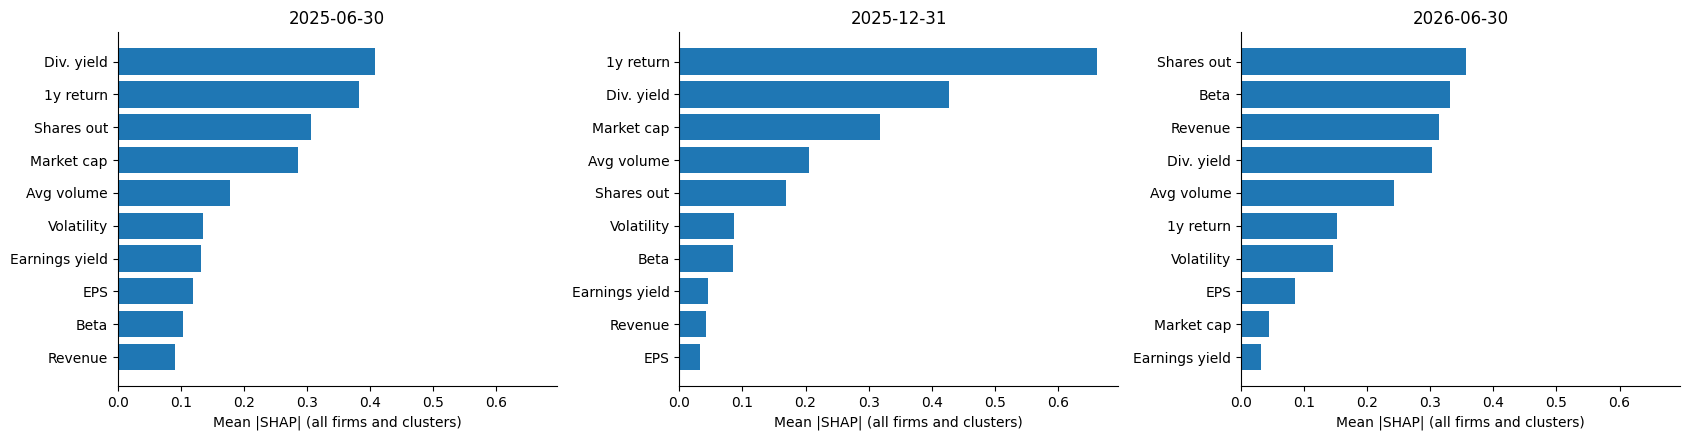

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True)
rows = []
for ax, d in zip(axes, DATES):
    imp = pd.Series(np.abs(sur[d]['explanation'].values).mean(axis=(0, 2)), index=NAMES).sort_values()
    ax.barh(imp.index, imp.values); ax.set_title(d); ax.set_xlabel('Mean |SHAP| (all firms and clusters)')
    rows.append(imp.rename(d))
table(pd.concat(rows, axis=1).loc[NAMES], 'shap_global_importance')
fig.tight_layout(); save(fig, 'shap_global'); plt.show()

### 10.2 Cluster-level importance
For each cluster: the mean |SHAP| of each feature for that cluster's own members. Singleton clusters are marked, because one firm cannot support a subgroup explanation.

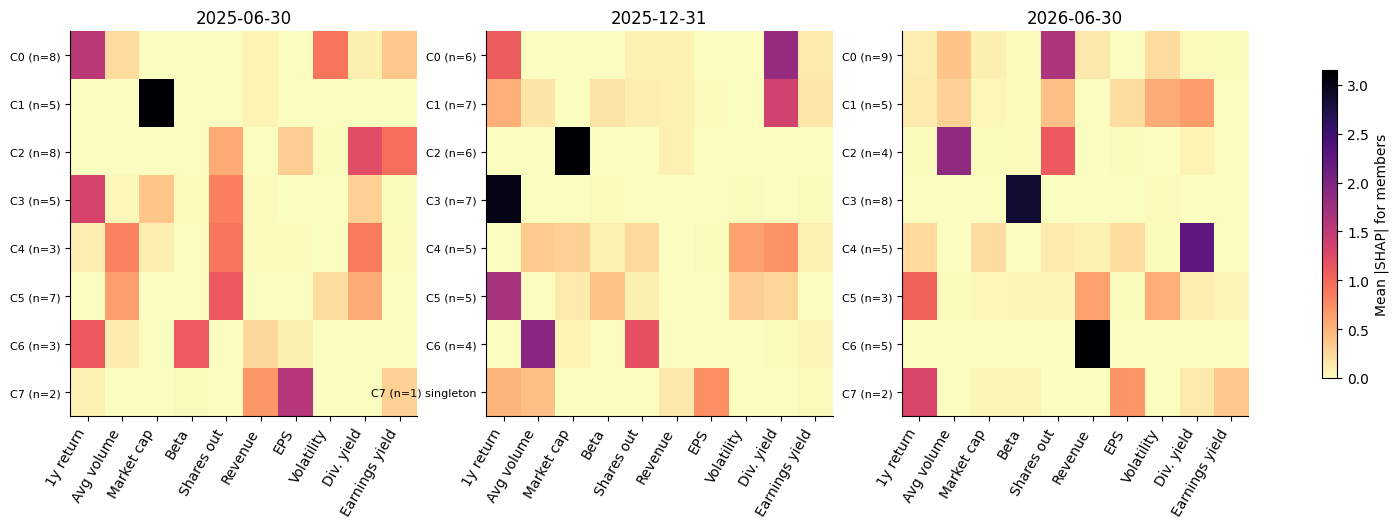

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
rows = []
for ax, d in zip(axes, DATES):
    s = sur[d]; vals = s['explanation'].values
    heat = pd.DataFrame([np.abs(vals[s['y'] == c, :, c]).mean(axis=0) for c in range(len(s['classes']))], columns=NAMES)
    sizes = np.bincount(s['y'])
    heat.index = [f'C{lab} (n={n}){" singleton" if n == 1 else ""}' for lab, n in zip(s['classes'], sizes)]
    rows.append(heat.assign(date=d))
    im = ax.imshow(heat, cmap='magma_r', aspect='auto')
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=60, ha='right'); ax.set_yticks(range(len(heat)), heat.index, fontsize=8)
    ax.set_title(d)
fig.colorbar(im, ax=axes, shrink=0.8, label='Mean |SHAP| for members')
table(pd.concat(rows), 'shap_cluster_importance'); save(fig, 'shap_cluster_heatmap'); plt.show()

### 10.3 Beeswarm plots per cluster
Each dot is a firm. Its colour is the feature value (red = high), and its position shows how much the value pushes the firm towards (right) or away from (left) that cluster.

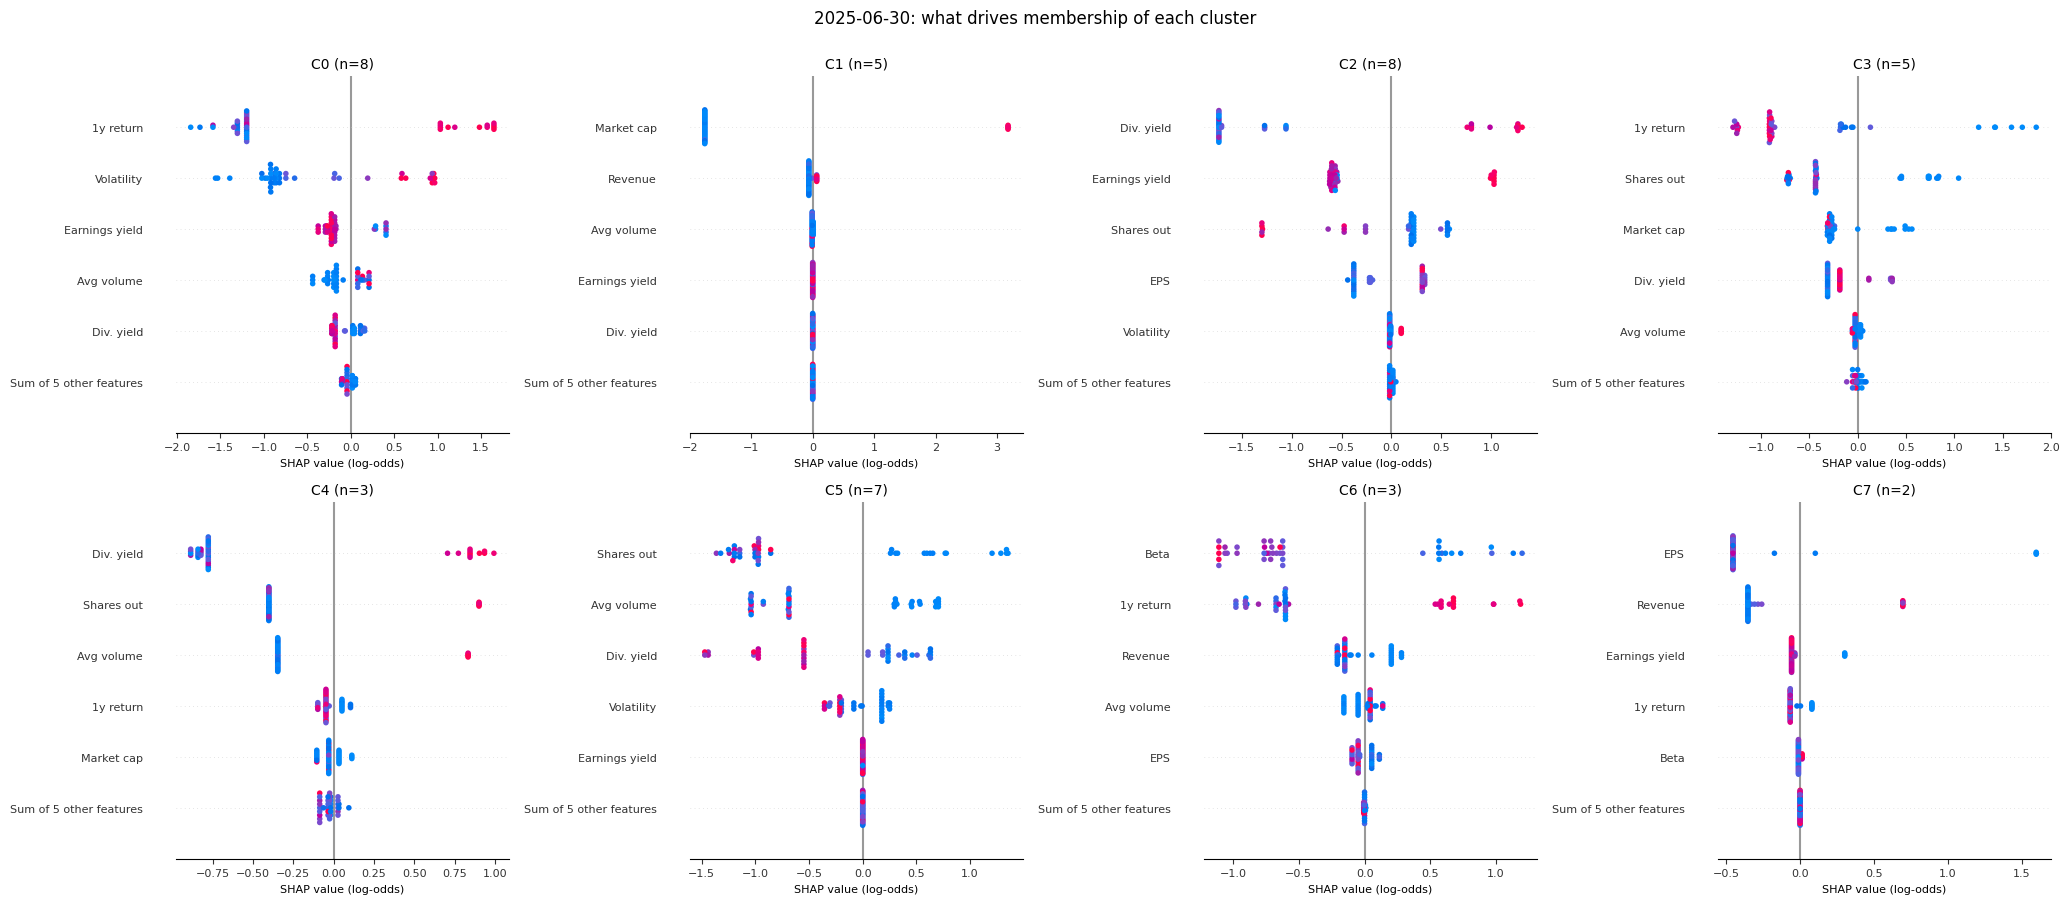

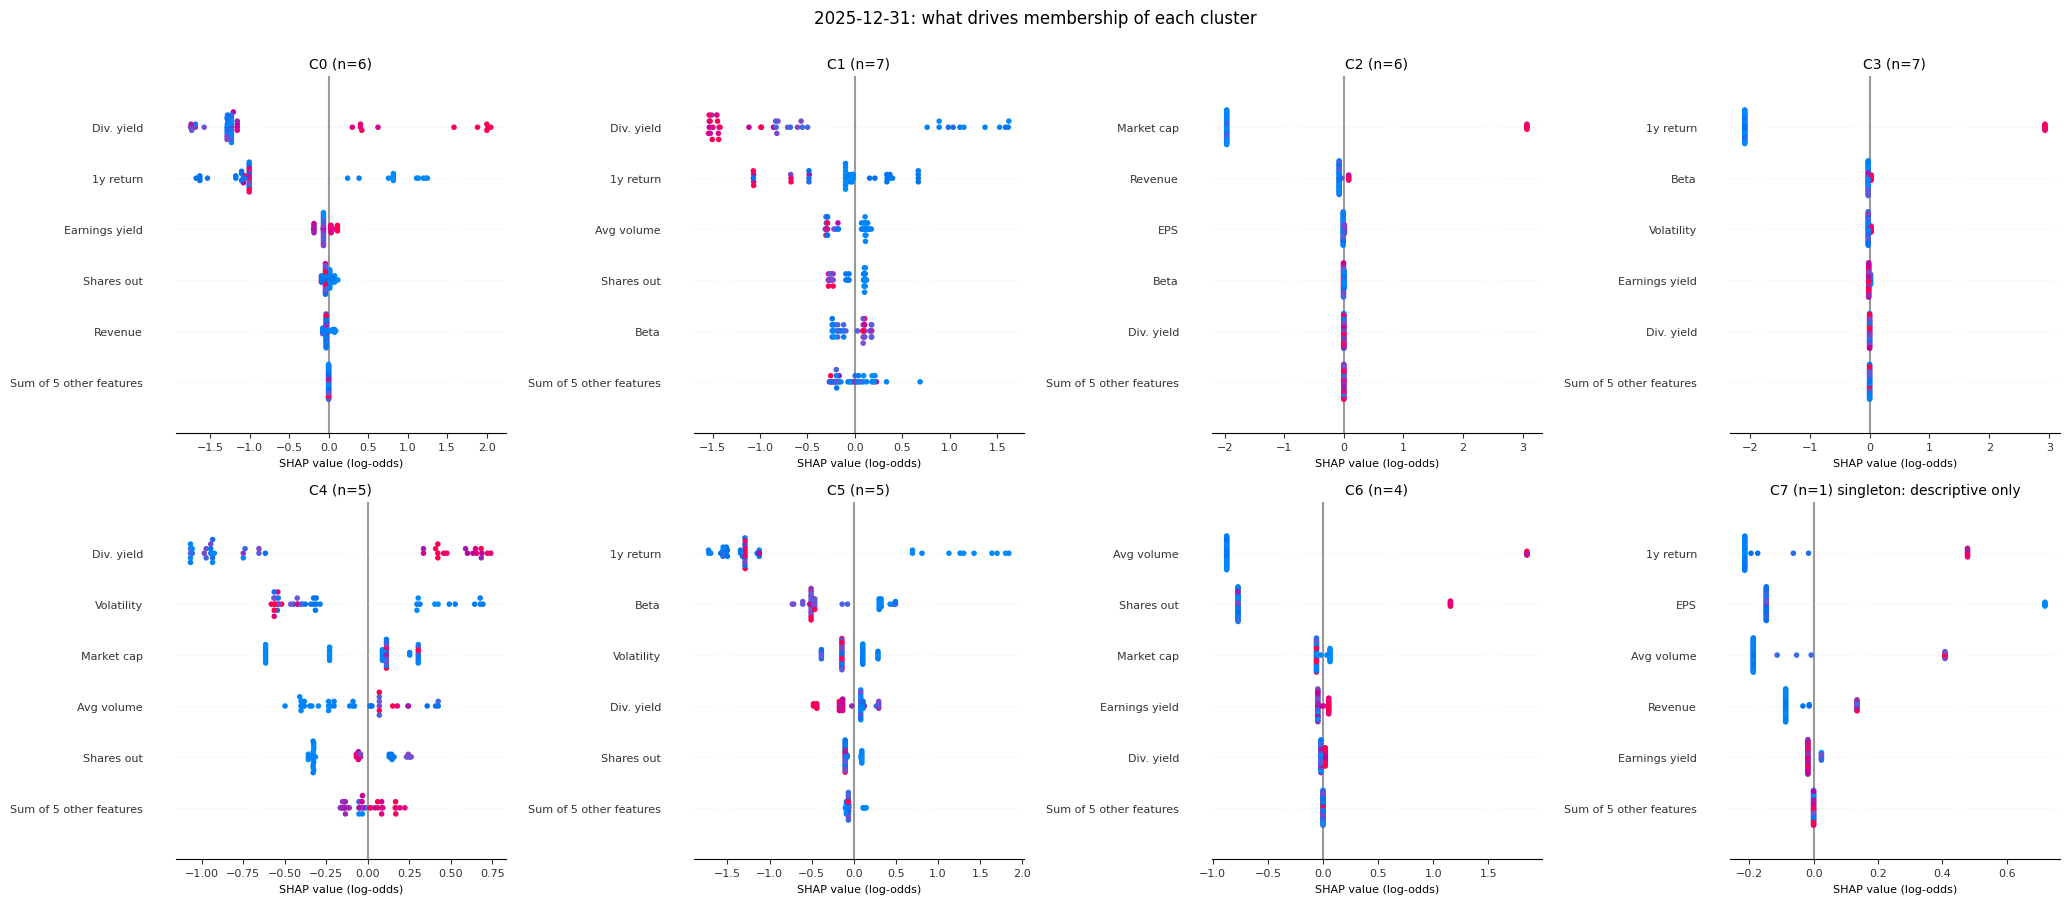

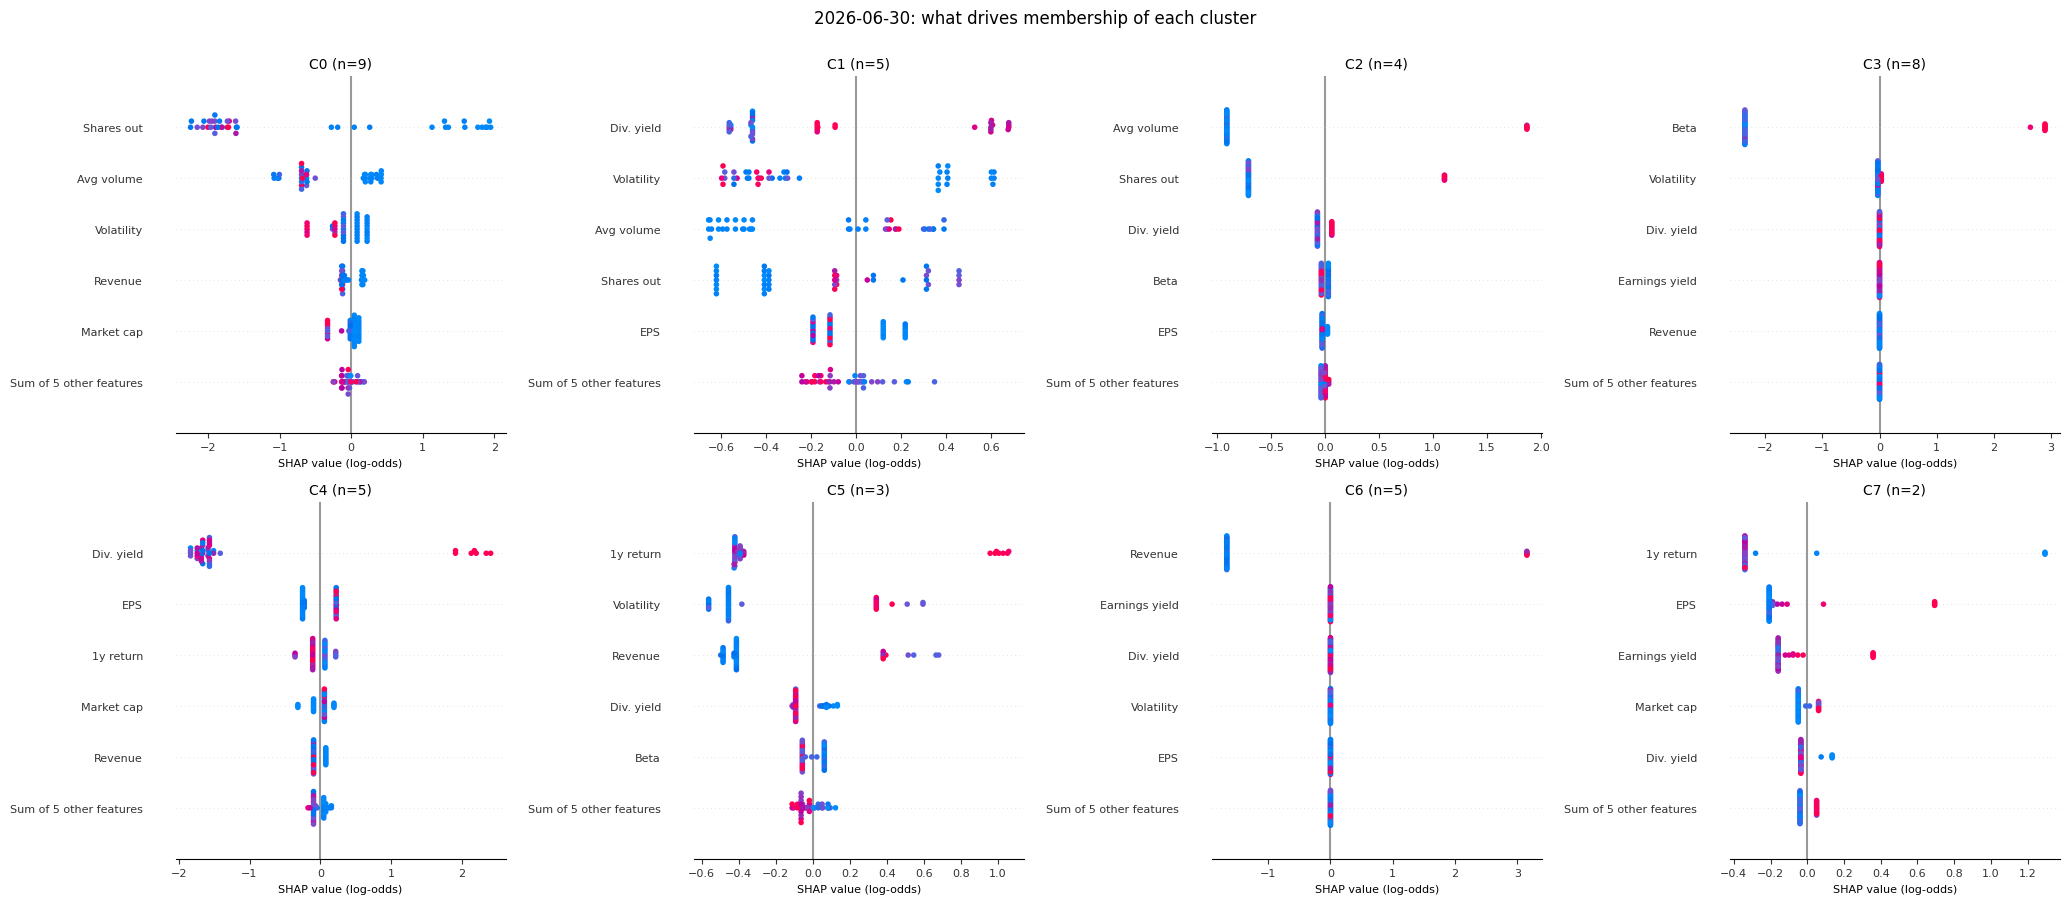

In [33]:
for d in DATES:
    s = sur[d]; n = len(s['classes'])
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(5.2 * ((n + 1) // 2), 9))
    for c, ax in zip(range(n), axes.flat):
        plt.sca(ax)
        shap.plots.beeswarm(s['explanation'][:, :, c], max_display=6, show=False, ax=ax, color_bar=False, plot_size=None)
        size = (s['y'] == c).sum()
        ax.set_title(f'C{s["classes"][c]} (n={size}){" singleton: descriptive only" if size == 1 else ""}', fontsize=10)
        ax.set_xlabel('SHAP value (log-odds)', fontsize=8); ax.tick_params(labelsize=8)
    for ax in axes.flat[n:]:
        ax.axis('off')
    fig.suptitle(f'{d}: what drives membership of each cluster', y=1.0)
    fig.tight_layout(); save(fig, f'shap_beeswarm_{d}'); plt.show()

### 10.4 Explaining one firm
A waterfall plot for one robustly sector-divergent firm shows which features place it in its cluster. Change `TICKER` to explore other firms.

BHG (Basic Materials) on 2026-06-30: cluster 6


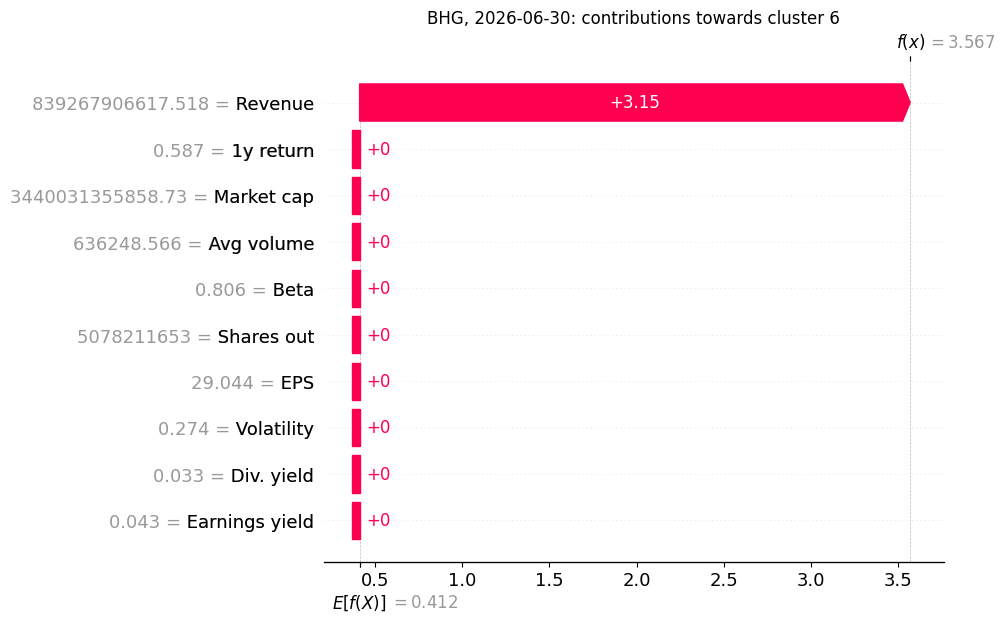

In [34]:
d = DATES[-1]
candidates = robust[robust.date == d].sort_values('divergent_share', ascending=False).ticker
TICKER = candidates.iat[0] if len(candidates) else base[d].ticker.iat[0]
s = sur[d]; i = int(np.flatnonzero(snaps[d].ticker.values == TICKER)[0]); c = s['y'][i]
print(f'{TICKER} ({info.loc[TICKER, "sector_label"]}) on {d}: cluster {s["classes"][c]}')
shap.plots.waterfall(s['explanation'][i, :, c], max_display=10, show=False)
plt.title(f'{TICKER}, {d}: contributions towards cluster {s["classes"][c]}')
save(plt.gcf(), f'shap_waterfall_{TICKER}_{d}'); plt.show()

## 11. Summary across the three cross-sections

In [35]:
summary = pd.DataFrame({
    d: {'Firms': len(snaps[d]),
        'Silhouette, t-SNE map': comparison.query('date == @d and reduction == "tsne" and clustering == "hierarchical"').silhouette_embedding.iat[0],
        'Davies–Bouldin, t-SNE map': comparison.query('date == @d and reduction == "tsne" and clustering == "hierarchical"').davies_bouldin_embedding.iat[0],
        'Silhouette, 10-feature space': comparison.query('date == @d and reduction == "tsne" and clustering == "hierarchical"').silhouette_features.iat[0],
        'Seed ARI, mean (min)': f"{seed_summary.loc[d, ('ari', 'mean')]:.2f} ({seed_summary.loc[d, ('ari', 'min')]:.2f})",
        'Sector ARI / NMI (mean of seeds)': f"{sector_agree[sector_agree.date == d].ari.mean():.2f} / {sector_agree[sector_agree.date == d].nmi.mean():.2f}",
        'Robust sector-divergent firms': int((robust.date == d).sum()),
        'T² outliers, feature space': int(t2[(t2.date == d)].feature_flag.sum()),
        'Surrogate OOF accuracy': '—' if sur[d]['oof'] is None else f"{sur[d]['oof']:.2f}"}
    for d in DATES})
table(summary, 'summary_across_dates')

,2025-06-30,2025-12-31,2026-06-30
Firms,41,41,41
"Silhouette, t-SNE map",0.570905,0.598058,0.641437
"Davies–Bouldin, t-SNE map",0.429116,0.44723,0.407119
"Silhouette, 10-feature space",0.181749,0.176727,0.222983
"Seed ARI, mean (min)",0.73 (0.53),0.92 (0.88),0.93 (0.84)
Sector ARI / NMI (mean of seeds),0.22 / 0.52,0.26 / 0.55,0.30 / 0.60
Robust sector-divergent firms,6,9,6
"T² outliers, feature space",3,1,2
Surrogate OOF accuracy,0.54,—,0.73


### Notes for writing the paper
* **Main claim.** The pipeline is applied to three historically correct cross-sections. Results are descriptive refits,
  not out-of-sample predictions. Dates are not train/validation/test sets.
* **Cluster quality.** Report both embedding scores (comparable with the SACJ paper) and feature-space scores.
  Feature-space silhouettes are low, so the groups are only loosely separated in the financial data.
* **Stability.** Do not claim perfect seed stability. Report the seed ARI range and base firm-level claims on robust (≥ 4/5 seeds) results.
* **Over time.** Report membership changes separately. Describe continuing firms as changing peer group only when the change exceeds seed noise.
* **SHAP.** Explanations describe a surrogate of the cluster labels. Report OOF fidelity, and note where it is not estimable.
* **Data caveats.** Retrospective public-source reconstruction, not point-in-time investor-observable data. Historical shares and
  sector labels are unverified. RNI fundamentals and two AGL volumes are imputed. Analyst ratings were unavailable.